# 🛒 E-commerce Sales & Customer Behaviour Analysis
### Olist Brazilian E-commerce · SQL (CTEs, joins, window functions) · Python · Power BI

---

## The business problem
You have joined **Olist**, a Brazilian marketplace that connects small sellers to large online storefronts. Leadership has three worries:

1. **Growth** – Where is revenue coming from, and is growth healthy or just seasonal?
2. **Customer experience** – Are slow deliveries hurting satisfaction (and therefore future sales)?
3. **Retention** – Do customers come back? Which customers are worth fighting for?

This notebook answers those questions with **SQL as the analysis engine** and Python for cleaning and visualisation, then turns the findings into recommendations.

## Skills demonstrated
| Skill | Where |
|---|---|
| Data cleaning & wrangling (ETL) | Section 2 |
| SQL: multi-table joins, CTEs, window functions (`LAG`, `RANK`, `NTILE`, `ROW_NUMBER`, running totals) | Sections 3-10 |
| Statistics (hypothesis test, effect size) | Section 5 |
| Data visualisation | Every section + dashboard in Section 11 |
| Business acumen (KPIs, RFM, cohort retention, scenario model) | Sections 6-7, 12 |
| Data storytelling | "💡 So what" callouts + Section 13 |
| Dashboarding | Section 11 exports → `powerbi/POWERBI_GUIDE.md` |

## How to run
`Kernel → Restart & Run All`. Data is loaded automatically (see Section 1).

## 1. Setup & data loading

In [1]:
import sqlite3, shutil, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, ORANGE, RED, GREEN, GREY = "#2563eb", "#f59e0b", "#dc2626", "#16a34a", "#94a3b8"

for d in ["data", "images", "sql", "powerbi/exports"]:
    Path(d).mkdir(parents=True, exist_ok=True)

In [2]:
# ---- Data loading: looks for the Olist CSVs wherever you put them ----
FILES = {
    "customers":   "olist_customers_dataset.csv",
    "orders":      "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments":    "olist_order_payments_dataset.csv",
    "reviews":     "olist_order_reviews_dataset.csv",
    "products":    "olist_products_dataset.csv",
    "sellers":     "olist_sellers_dataset.csv",
    "translation": "product_category_name_translation.csv",
}

def have_all(folder):
    return all((Path(folder) / f).exists() for f in FILES.values())

def find_data_dir():
    # exact folders first (fast), then search everything underneath the notebook's folder
    for c in [Path("data"), Path("."), Path(".."), Path("input"), Path("/kaggle/input"), Path("/mnt/data")]:
        if c.exists() and have_all(c):
            return c
    for p in Path(".").rglob(FILES["orders"]):
        if have_all(p.parent):
            return p.parent
    return None

IS_SYNTHETIC = False
DATA_DIR = find_data_dir()

if DATA_DIR is not None:
    DATA_SOURCE = f"real Olist data (found in '{DATA_DIR.resolve()}')"
else:
    try:                                   # optional: auto-download from Kaggle
        import kagglehub
        src = Path(kagglehub.dataset_download("olistbr/brazilian-ecommerce"))
        DATA_DIR = Path("data")
        for f in FILES.values():
            shutil.copy(next(src.rglob(f)), DATA_DIR / f)
        DATA_SOURCE = "real Olist data (downloaded from Kaggle)"
    except Exception:
        try:                               # last resort: fake demo data (needs src/make_sample_data.py)
            from src.make_sample_data import generate
            DATA_DIR = generate("data/sample")
            IS_SYNTHETIC = True
            DATA_SOURCE = "SYNTHETIC demo data"
        except Exception:
            missing = [f for f in FILES.values() if not any(Path(".").rglob(f))]
            raise FileNotFoundError(
                "Could not find the Olist CSV files.\n"
                f"Notebook is running from: {Path('.').resolve()}\n"
                f"Files not found anywhere under it: {missing}\n"
                "Fix: upload the CSVs into the same folder as this notebook (or into a 'data' subfolder), then re-run."
            ) from None

print(f"Data source: {DATA_SOURCE}")
if IS_SYNTHETIC:
    print("=" * 78)
    print("⚠️  RUNNING ON FAKE DATA. Numbers below are illustrative only.")
    print("=" * 78)

raw = {name: pd.read_csv(DATA_DIR / f) for name, f in FILES.items()}
pd.DataFrame({n: {"rows": len(d), "columns": d.shape[1]} for n, d in raw.items()}).T

Data source: real Olist data (found in '/home/jovyan')


,rows,columns
customers,99441,5
orders,99441,8
order_items,112650,7
payments,103886,5
reviews,99224,7
products,32951,9
sellers,3095,4
translation,71,2


### Data model
Eight tables. The join keys that matter:

```
customers ──(customer_id)── orders ──(order_id)── order_items ──(product_id)── products ──(category)── translation
                              │                        └──(seller_id)── sellers
                              ├──(order_id)── payments
                              └──(order_id)── reviews
```

> ⚠️ **Classic gotcha:** `customer_id` is generated **per order**. The real person is `customer_unique_id`. If you count `customer_id` you will conclude that *nobody ever buys twice*. Every customer-level metric in this notebook uses `customer_unique_id`.

## 2. Data cleaning & quality audit
Before any analysis: profile the data, find the problems, fix them, and **log every decision** so the work is reproducible and defensible.

In [3]:
# 2.1  Profile: missing values and duplicates per table
audit = pd.DataFrame({
    name: {"rows": len(df),
           "missing cells": int(df.isna().sum().sum()),
           "fully duplicated rows": int(df.duplicated().sum())}
    for name, df in raw.items()}).T
display(audit)

miss = {n: d.isna().sum()[d.isna().sum() > 0] for n, d in raw.items()}
miss = {n: s for n, s in miss.items() if len(s)}
for n, s in miss.items():
    print(f"\nColumns with missing values in `{n}`:")
    print((s.to_frame("missing").assign(pct=lambda x: 100 * x.missing / len(raw[n]))).round(1).to_string())

,rows,missing cells,fully duplicated rows
customers,99441,0,0
orders,99441,4908,0
order_items,112650,0,0
payments,103886,0,0
reviews,99224,145903,0
products,32951,2448,0
sellers,3095,0,0
translation,71,0,0



Columns with missing values in `orders`:
                               missing  pct
order_approved_at                  160 0.20
order_delivered_carrier_date      1783 1.80
order_delivered_customer_date     2965 3.00

Columns with missing values in `reviews`:
                        missing   pct
review_comment_title      87656 88.30
review_comment_message    58247 58.70

Columns with missing values in `products`:
                            missing  pct
product_category_name           610 1.90
product_name_lenght             610 1.90
product_description_lenght      610 1.90
product_photos_qty              610 1.90
product_weight_g                  2 0.00
product_length_cm                 2 0.00
product_height_cm                 2 0.00
product_width_cm                  2 0.00


In [4]:
# 2.2  Clean, and keep a log of every fix
clean_log = []
def log(table, issue, rows, action):
    clean_log.append({"table": table, "issue": issue, "rows affected": int(rows), "action": action})

tables = {k: v.copy() for k, v in raw.items()}

# --- orders: parse dates, then check logic
orders = tables["orders"]
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c], errors="coerce")
log("orders", "Date columns stored as text", len(orders), "Converted to datetime")

impossible = orders.order_delivered_customer_date < orders.order_purchase_timestamp
log("orders", "Delivered BEFORE purchased (impossible)", impossible.sum(), "Delivery date set to NULL")
orders.loc[impossible, "order_delivered_customer_date"] = pd.NaT

missing_dd = (orders.order_status == "delivered") & orders.order_delivered_customer_date.isna()
log("orders", "Status 'delivered' but no delivery date", missing_dd.sum(), "Kept; excluded from delivery-time analysis")

not_deliv = (orders.order_status != "delivered") & orders.order_delivered_customer_date.notna()
log("orders", "Delivery date present on non-delivered order", not_deliv.sum(), "Delivery date set to NULL")
orders.loc[not_deliv, "order_delivered_customer_date"] = pd.NaT

# --- order_items
items = tables["order_items"]
items["shipping_limit_date"] = pd.to_datetime(items["shipping_limit_date"], errors="coerce")
bad_price = (items.price <= 0) | (items.freight_value < 0)
log("order_items", "Price <= 0 or negative freight", bad_price.sum(), "Rows removed")
tables["order_items"] = items[~bad_price]

# --- products: typo'd column names + missing categories
prod = tables["products"].rename(columns={"product_name_lenght": "product_name_length",
                                          "product_description_lenght": "product_description_length"})
log("products", "Missing category name", prod.product_category_name.isna().sum(), "Filled with 'unknown'")
prod["product_category_name"] = prod.product_category_name.fillna("unknown")
tables["products"] = prod

# --- customers: inconsistent text formatting
cust = tables["customers"]
messy = (cust.customer_city != cust.customer_city.str.strip().str.lower())
log("customers", "City has inconsistent case / whitespace", messy.sum(), "Stripped and lower-cased")
cust["customer_city"] = cust.customer_city.str.strip().str.lower()
cust["customer_state"] = cust.customer_state.str.strip().str.upper()

# --- reviews: dates + (dedupe handled in SQL with ROW_NUMBER, see Section 3)
rev = tables["reviews"]
for c in ["review_creation_date", "review_answer_timestamp"]:
    rev[c] = pd.to_datetime(rev[c], errors="coerce")
multi = rev.groupby("order_id").size()
log("reviews", "Orders with more than one review", (multi > 1).sum(), "Keep only the latest review per order (SQL window function)")

# --- payments
pay = tables["payments"]
log("payments", "payment_value = 0", (pay.payment_value == 0).sum(), "Kept (vouchers / not_defined); noted")

display(pd.DataFrame(clean_log))

,table,issue,rows affected,action
0,orders,Date columns stored as text,99441,Converted to datetime
1,orders,Delivered BEFORE purchased (impossible),0,Delivery date set to NULL
2,orders,Status 'delivered' but no delivery date,8,Kept; excluded from delivery-time analysis
3,orders,Delivery date present on non-delivered order,6,Delivery date set to NULL
4,order_items,Price <= 0 or negative freight,0,Rows removed
5,products,Missing category name,610,Filled with 'unknown'
6,customers,City has inconsistent case / whitespace,0,Stripped and lower-cased
7,reviews,Orders with more than one review,547,Keep only the latest review per order (SQL win...
8,payments,payment_value = 0,9,Kept (vouchers / not_defined); noted


In [5]:
# 2.3  Load clean tables into a SQLite database (stores dates as ISO text so SQL date functions work)
DB_PATH = Path("data/olist.db")
if DB_PATH.exists():
    DB_PATH.unlink()
con = sqlite3.connect(DB_PATH)

for name, df in tables.items():
    df = df.copy()
    for c in df.select_dtypes(include=["datetime"]).columns:
        df[c] = df[c].dt.strftime("%Y-%m-%d %H:%M:%S")
    df.to_sql(name if name != "payments" else "order_payments", con, index=False)

# indexes on join keys → fast joins
for stmt in [
    "CREATE INDEX ix_orders_cust ON orders(customer_id)",
    "CREATE INDEX ix_items_order ON order_items(order_id)",
    "CREATE INDEX ix_items_prod  ON order_items(product_id)",
    "CREATE INDEX ix_items_sell  ON order_items(seller_id)",
    "CREATE INDEX ix_pay_order   ON order_payments(order_id)",
    "CREATE INDEX ix_rev_order   ON reviews(order_id)",
    "CREATE INDEX ix_cust_uniq   ON customers(customer_unique_id)",
]:
    con.execute(stmt)
con.commit()
print("Tables in database:", [r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type='table'")])

Tables in database: ['customers', 'orders', 'order_items', 'order_payments', 'reviews', 'products', 'sellers', 'translation']


## 3. Analytical views (SQL)
Rather than repeat the same 6-table join in every query, I build two reusable **views** — the SQL equivalent of a fact table in a data warehouse.

| View | Grain | Purpose |
|---|---|---|
| `v_reviews_dedup` | 1 row per order | Latest review only (uses `ROW_NUMBER()`) |
| `v_sales` | 1 row per **order item** | Revenue, category, geography, seller, review |
| `v_delivered_orders` | 1 row per **delivered order** | Delivery performance, satisfaction |

**Business rules (documented so nobody has to guess):**
- Revenue = item `price` (excludes freight). GMV = price + freight.
- Canceled and unavailable orders are excluded from sales.
- Analysis window = **2017-01-01 → 2018-08-31**. 2016 has only a handful of orders and Sept–Oct 2018 are incomplete; including them would distort growth numbers.

In [6]:
START_DATE, END_DATE = "2017-01-01", "2018-09-01"   # END is exclusive

VIEWS_SQL = f'''
-- 1) Latest review per order. Some orders have several reviews -> keep the most recent
CREATE VIEW v_reviews_dedup AS
SELECT order_id, review_score
FROM (
    SELECT order_id, review_score,
           ROW_NUMBER() OVER (PARTITION BY order_id
                              ORDER BY review_answer_timestamp DESC, review_id) AS rn
    FROM reviews
)
WHERE rn = 1;

-- 2) Sales fact view: one row per order item (5 joins)
CREATE VIEW v_sales AS
SELECT
    oi.order_id,
    oi.order_item_id,
    o.order_status,
    o.order_purchase_timestamp                          AS purchase_ts,
    substr(o.order_purchase_timestamp, 1, 10)           AS purchase_date,
    substr(o.order_purchase_timestamp, 1, 7)            AS order_month,
    c.customer_unique_id,
    c.customer_state,
    c.customer_city,
    oi.seller_id,
    s.seller_state,
    oi.product_id,
    COALESCE(t.product_category_name_english, p.product_category_name, 'unknown') AS category,
    oi.price,
    oi.freight_value,
    oi.price + oi.freight_value                         AS gmv,
    r.review_score
FROM order_items oi
JOIN orders o               ON o.order_id = oi.order_id
JOIN customers c            ON c.customer_id = o.customer_id
LEFT JOIN products p        ON p.product_id = oi.product_id
LEFT JOIN translation t     ON t.product_category_name = p.product_category_name
LEFT JOIN sellers s         ON s.seller_id = oi.seller_id
LEFT JOIN v_reviews_dedup r ON r.order_id = oi.order_id
WHERE o.order_status NOT IN ('canceled', 'unavailable')
  AND o.order_purchase_timestamp >= '{START_DATE}'
  AND o.order_purchase_timestamp <  '{END_DATE}';

-- 3) Delivered-orders view: one row per order (CTE inside a view)
CREATE VIEW v_delivered_orders AS
WITH order_value AS (
    SELECT order_id, SUM(price) AS revenue, SUM(freight_value) AS freight, COUNT(*) AS items
    FROM order_items
    GROUP BY order_id
)
SELECT
    o.order_id,
    c.customer_unique_id,
    c.customer_state,
    o.order_purchase_timestamp                                                        AS purchase_ts,
    substr(o.order_purchase_timestamp, 1, 10)                                         AS purchase_date,
    ROUND(julianday(o.order_delivered_customer_date) - julianday(o.order_purchase_timestamp), 2) AS delivery_days,
    ROUND(julianday(o.order_delivered_customer_date) - julianday(o.order_estimated_delivery_date), 2) AS days_vs_estimate,
    CASE WHEN julianday(o.order_delivered_customer_date) > julianday(o.order_estimated_delivery_date)
         THEN 1 ELSE 0 END                                                            AS is_late,
    ov.revenue, ov.freight, ov.items,
    r.review_score
FROM orders o
JOIN customers c            ON c.customer_id = o.customer_id
JOIN order_value ov         ON ov.order_id = o.order_id
LEFT JOIN v_reviews_dedup r ON r.order_id = o.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND o.order_purchase_timestamp >= '{START_DATE}'
  AND o.order_purchase_timestamp <  '{END_DATE}';
'''
con.executescript(VIEWS_SQL)

# helpers used for the rest of the notebook
QUERIES = {}
def q(name, sql):
    # run a SQL query, remember it (exported to sql/ at the end) and return a DataFrame
    QUERIES[name] = sql.strip()
    return pd.read_sql_query(sql, con)

def say(text):
    display(Markdown(text))

def save_fig(fig, name):
    fig.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight", facecolor="white")

def brl(x, pos=None):
    return f"R${x/1e6:.1f}M" if abs(x) >= 1e6 else f"R${x/1e3:.0f}K" if abs(x) >= 1e3 else f"R${x:.0f}"

In [7]:
# Data-quality gate: the joins must not duplicate or drop rows
expected = pd.read_sql_query(f'''
    SELECT COUNT(*) AS n, ROUND(SUM(oi.price), 2) AS rev
    FROM order_items oi JOIN orders o ON o.order_id = oi.order_id
    WHERE o.order_status NOT IN ('canceled','unavailable')
      AND o.order_purchase_timestamp >= '{START_DATE}' AND o.order_purchase_timestamp < '{END_DATE}'
''', con)
actual = pd.read_sql_query("SELECT COUNT(*) AS n, ROUND(SUM(price), 2) AS rev FROM v_sales", con)
assert expected.n[0] == actual.n[0], "Row count mismatch: a join is fanning out or dropping rows"
assert abs(expected.rev[0] - actual.rev[0]) < 1, "Revenue mismatch between source and view"
print(f"✅ Reconciliation passed: {actual.n[0]:,} order items, R${actual.rev[0]:,.0f} revenue — identical to source tables.")

✅ Reconciliation passed: 111,752 order items, R$13,449,530 revenue — identical to source tables.


## 4. Executive KPIs

In [8]:
kpi = q("00_headline_kpis", '''
SELECT
    COUNT(DISTINCT order_id)                                  AS orders,
    COUNT(DISTINCT customer_unique_id)                        AS customers,
    COUNT(DISTINCT seller_id)                                 AS sellers,
    ROUND(SUM(price), 0)                                      AS revenue,
    ROUND(SUM(price) / COUNT(DISTINCT order_id), 2)           AS avg_order_value,
    ROUND(100.0 * SUM(freight_value) / SUM(price), 1)         AS freight_pct_of_revenue,
    ROUND(AVG(review_score), 2)                               AS avg_review_score
FROM v_sales
''').iloc[0]

late_pct = pd.read_sql_query("SELECT ROUND(100.0*AVG(is_late),1) AS x FROM v_delivered_orders", con).x[0]
say(f'''
| 🧾 Orders | 👥 Customers | 🏪 Sellers | 💰 Revenue | 🛍️ Avg order value | 🚚 Freight / revenue | ⭐ Avg review | ⏰ Late deliveries |
|---|---|---|---|---|---|---|---|
| **{kpi.orders:,.0f}** | **{kpi.customers:,.0f}** | **{kpi.sellers:,.0f}** | **R${kpi.revenue:,.0f}** | **R${kpi.avg_order_value:,.2f}** | **{kpi.freight_pct_of_revenue}%** | **{kpi.avg_review_score}** | **{late_pct}%** |
''')


| 🧾 Orders | 👥 Customers | 🏪 Sellers | 💰 Revenue | 🛍️ Avg order value | 🚚 Freight / revenue | ⭐ Avg review | ⏰ Late deliveries |
|---|---|---|---|---|---|---|---|
| **97,905** | **94,703** | **3,029** | **R$13,449,530** | **R$137.37** | **16.6%** | **4.05** | **8.1%** |


## 5. Is growth healthy? Monthly revenue & MoM growth
**SQL techniques:** CTE + `LAG()` window function.

,order_month,revenue,orders,customers,avg_order_value,mom_growth_pct,rev_3m_avg
12,2018-01,"945,456.29",7187,7088,131.55,27.40,"897,167.41"
13,2018-02,"837,895.43",6624,6468,126.49,-11.40,"841,845.17"
14,2018-03,"981,051.06",7168,7077,136.87,17.10,"921,467.59"
15,2018-04,"993,592.98",6919,6863,143.60,1.30,"937,513.16"
16,2018-05,"992,871.75",6833,6775,145.31,-0.10,"989,171.93"
17,2018-06,"863,265.53",6145,6106,140.48,-13.10,"949,910.09"
18,2018-07,"878,044.27",6233,6172,140.87,1.70,"911,393.85"
19,2018-08,"848,860.10",6421,6380,132.20,-3.30,"863,389.97"


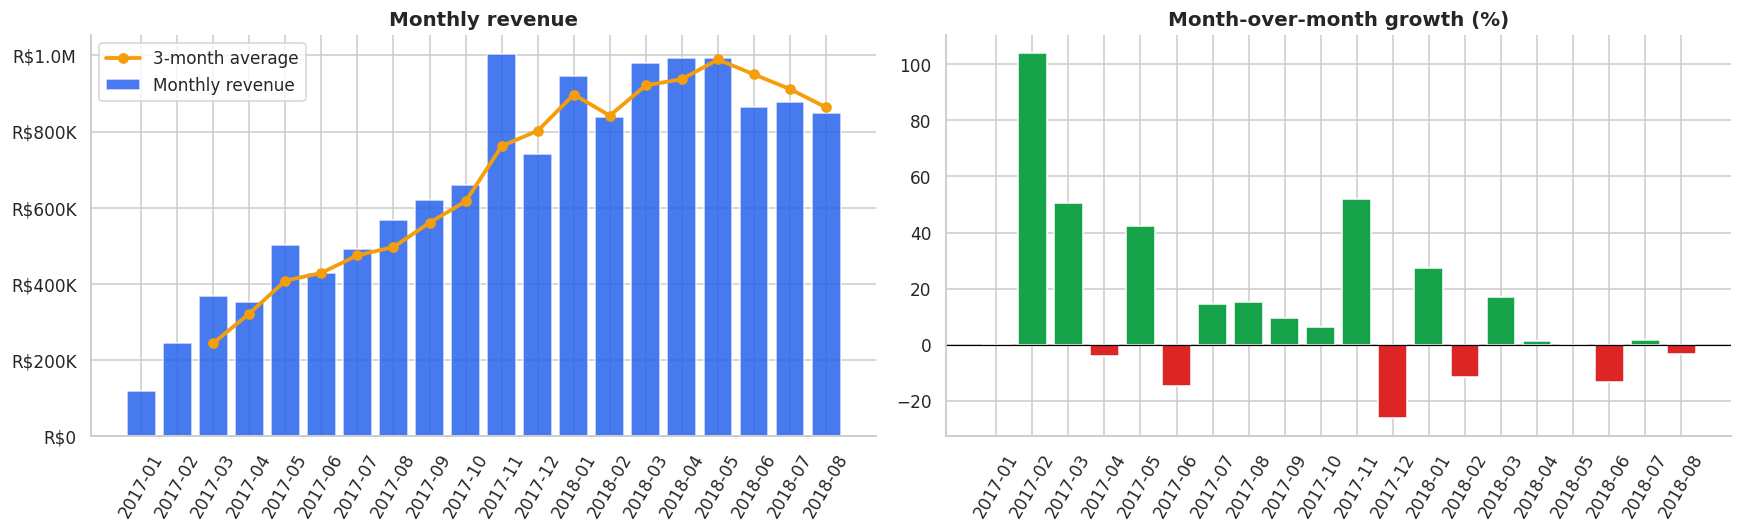


> 💡 **So what?**
> - Revenue peaked in **2017-11** at **R$1,003,862** — check whether that is a seasonal spike (Black Friday) or a genuine step-change before extrapolating it.
> - Jan–Aug 2018 revenue is **+138%** vs Jan–Aug 2017 (like-for-like months, so incomplete 2018 data doesn't mislead).
> - Comparing the last 6 months with the first 6: monthly orders **+177%**, average order value **-2%** → growth comes from **more orders rather than bigger baskets**.


In [9]:
monthly = q("01_monthly_revenue_growth", '''
WITH monthly AS (
    SELECT order_month,
           SUM(price)                  AS revenue,
           COUNT(DISTINCT order_id)    AS orders,
           COUNT(DISTINCT customer_unique_id) AS customers
    FROM v_sales
    GROUP BY order_month
)
SELECT order_month,
       ROUND(revenue, 2)                                  AS revenue,
       orders,
       customers,
       ROUND(revenue / orders, 2)                         AS avg_order_value,
       ROUND(100.0 * (revenue - LAG(revenue) OVER (ORDER BY order_month))
                   / LAG(revenue) OVER (ORDER BY order_month), 1) AS mom_growth_pct
FROM monthly
ORDER BY order_month
''')
monthly["rev_3m_avg"] = monthly.revenue.rolling(3).mean()
display(monthly.tail(8))

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].bar(monthly.order_month, monthly.revenue, color=BLUE, alpha=.85, label="Monthly revenue")
ax[0].plot(monthly.order_month, monthly.rev_3m_avg, color=ORANGE, lw=2.5, marker="o", label="3-month average")
ax[0].yaxis.set_major_formatter(mtick.FuncFormatter(brl))
ax[0].set_title("Monthly revenue"); ax[0].tick_params(axis="x", rotation=60); ax[0].legend()
colors = [GREEN if v >= 0 else RED for v in monthly.mom_growth_pct.fillna(0)]
ax[1].bar(monthly.order_month, monthly.mom_growth_pct.fillna(0), color=colors)
ax[1].axhline(0, color="black", lw=.8)
ax[1].set_title("Month-over-month growth (%)"); ax[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); save_fig(fig, "01_monthly_revenue"); plt.show()

peak = monthly.loc[monthly.revenue.idxmax()]
first6, last6 = monthly.head(6), monthly.tail(6)
aov_chg = 100 * (last6.avg_order_value.mean() / first6.avg_order_value.mean() - 1)
ord_chg = 100 * (last6.orders.mean() / first6.orders.mean() - 1)
growth_driver = ("more orders rather than bigger baskets" if abs(aov_chg) < abs(ord_chg) / 3
                 else "a mix of more orders and bigger baskets")
m = monthly.assign(year=monthly.order_month.str[:4], mm=monthly.order_month.str[5:])
ytd = m[m.mm <= "08"].groupby("year").revenue.sum()
yoy = (ytd.get("2018", np.nan) / ytd.get("2017", np.nan) - 1) * 100
say(f'''
> 💡 **So what?**
> - Revenue peaked in **{peak.order_month}** at **R${peak.revenue:,.0f}** — check whether that is a seasonal spike (Black Friday) or a genuine step-change before extrapolating it.
> - Jan–Aug 2018 revenue is **{yoy:+.0f}%** vs Jan–Aug 2017 (like-for-like months, so incomplete 2018 data doesn't mislead).
> - Comparing the last 6 months with the first 6: monthly orders **{ord_chg:+.0f}%**, average order value **{aov_chg:+.0f}%** → growth comes from **{growth_driver}**.
''')

## 6. What drives revenue? Category performance & Pareto analysis
**SQL techniques:** 4-table join, `SUM() OVER ()` for share of total, running total window for the cumulative (Pareto) curve.

,category,revenue,orders,avg_review,pct_of_total,cumulative_pct
0,health_beauty,"1,251,146.00",8757,4.15,9.30,9.30
1,watches_gifts,"1,194,825.00",5599,4.03,8.88,18.19
2,bed_bath_table,"1,035,485.00",9394,3.90,7.70,25.89
3,sports_leisure,"977,729.00",7656,4.12,7.27,33.15
4,computers_accessories,"902,923.00",6636,3.95,6.71,39.87
5,furniture_decor,"721,584.00",6373,3.92,5.37,45.23
6,housewares,"625,539.00",5838,4.07,4.65,49.88
7,cool_stuff,"619,724.00",3609,4.16,4.61,54.49
8,auto,"585,177.00",3863,4.08,4.35,58.84
9,garden_tools,"479,650.00",3500,4.06,3.57,62.41


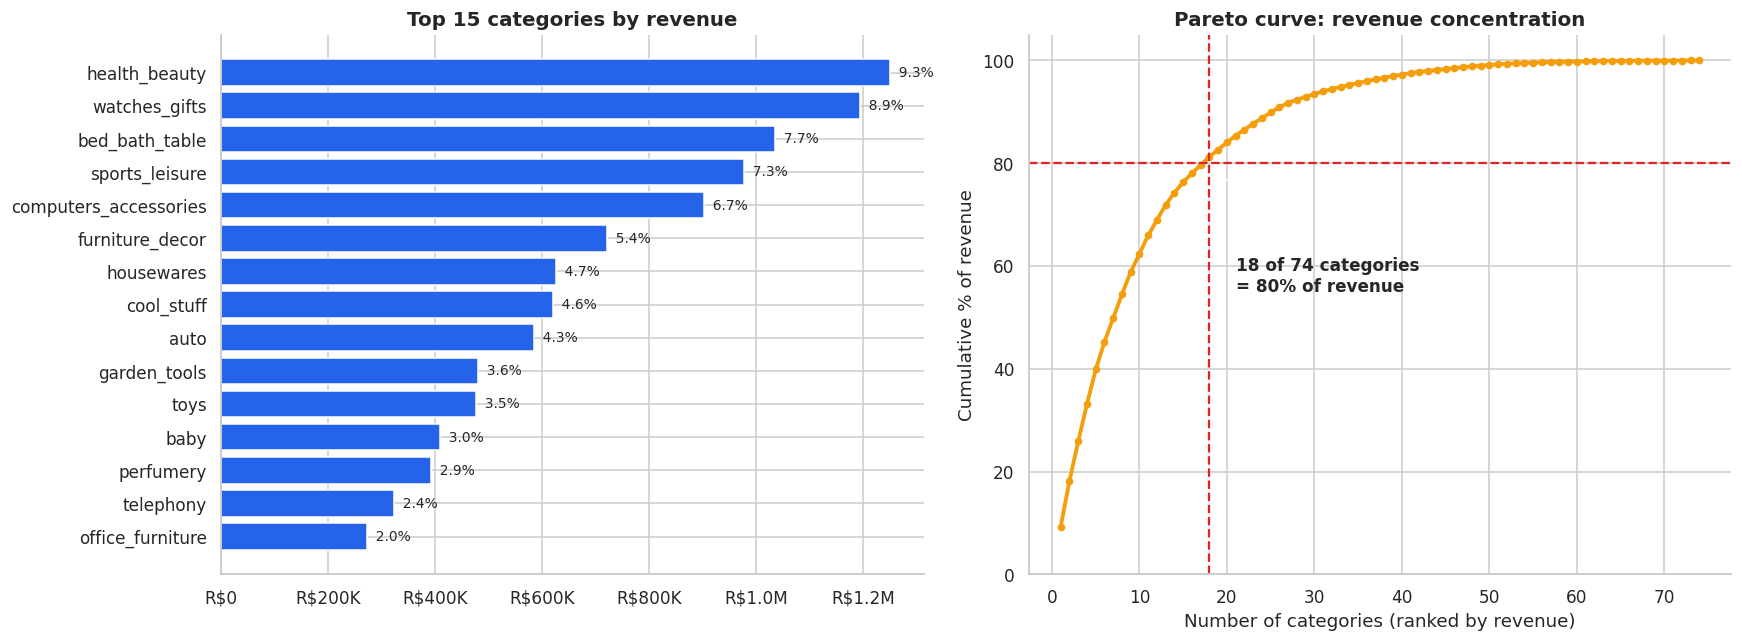

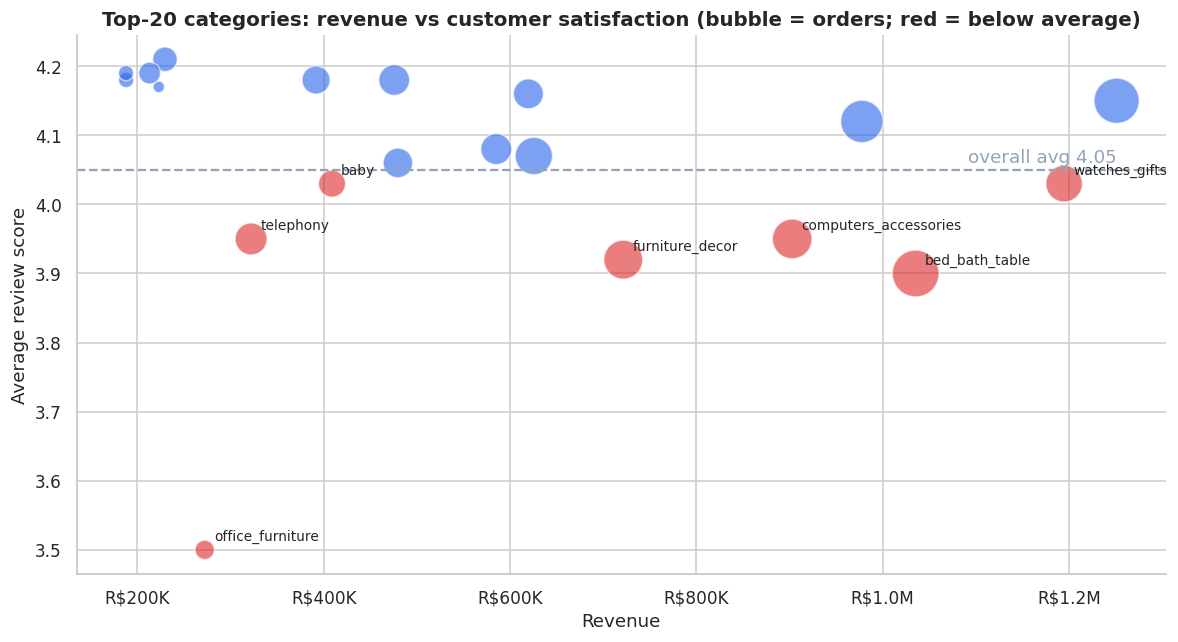


> 💡 **So what?**
> - **18 categories generate 80% of revenue** — merchandising, inventory and marketing effort should be concentrated there.
> - The top category alone is **9.3%** of revenue (**health_beauty**).
> - **7 high-revenue categories score below the platform average review** (watches_gifts, bed_bath_table, computers_accessories, furniture_decor…). Big and unhappy is the most expensive combination: fix quality / sellers here first.


In [10]:
cat = q("02_category_pareto", '''
WITH cat AS (
    SELECT category,
           SUM(price)                    AS revenue,
           COUNT(DISTINCT order_id)      AS orders,
           ROUND(AVG(review_score), 2)   AS avg_review
    FROM v_sales
    GROUP BY category
)
SELECT category, ROUND(revenue, 0) AS revenue, orders, avg_review,
       ROUND(100.0 * revenue / SUM(revenue) OVER (), 2) AS pct_of_total,
       ROUND(100.0 * SUM(revenue) OVER (ORDER BY revenue DESC
                                        ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW)
                   / SUM(revenue) OVER (), 2)           AS cumulative_pct
FROM cat
ORDER BY revenue DESC
''')
display(cat.head(10))

top = cat.head(15).iloc[::-1]
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].barh(top.category, top.revenue, color=BLUE)
ax[0].xaxis.set_major_formatter(mtick.FuncFormatter(brl)); ax[0].set_title("Top 15 categories by revenue")
for y, (v, p) in enumerate(zip(top.revenue, top.pct_of_total)):
    ax[0].text(v, y, f"  {p:.1f}%", va="center", fontsize=9)

ax[1].plot(range(1, len(cat) + 1), cat.cumulative_pct, color=ORANGE, lw=2.5, marker="o", ms=4)
ax[1].axhline(80, color=RED, ls="--"); ax[1].set_ylim(0, 105)
n80 = int((cat.cumulative_pct < 80).sum() + 1)
ax[1].axvline(n80, color=RED, ls="--")
ax[1].annotate(f"{n80} of {len(cat)} categories\n= 80% of revenue", (n80, 80), xytext=(n80 + 3, 55),
               arrowprops=dict(arrowstyle="->"), fontsize=11, fontweight="bold")
ax[1].set_xlabel("Number of categories (ranked by revenue)"); ax[1].set_ylabel("Cumulative % of revenue")
ax[1].set_title("Pareto curve: revenue concentration")
plt.tight_layout(); save_fig(fig, "02_category_pareto"); plt.show()

# Revenue vs satisfaction: which BIG categories disappoint customers?
big = cat.head(20).copy()
overall = kpi.avg_review_score
fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(big.revenue, big.avg_review, s=big.orders / big.orders.max() * 900 + 40,
           c=np.where(big.avg_review < overall, RED, BLUE), alpha=.6, edgecolor="white")
ax.axhline(overall, color=GREY, ls="--"); ax.text(big.revenue.max(), overall + .01, f"overall avg {overall}", ha="right", color=GREY)
for _, r in big[big.avg_review < overall].iterrows():
    ax.annotate(r.category, (r.revenue, r.avg_review), xytext=(6, 6), textcoords="offset points", fontsize=9)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(brl))
ax.set_xlabel("Revenue"); ax.set_ylabel("Average review score")
ax.set_title("Top-20 categories: revenue vs customer satisfaction (bubble = orders; red = below average)")
plt.tight_layout(); save_fig(fig, "02b_category_revenue_vs_review"); plt.show()

at_risk_cats = big[big.avg_review < overall].sort_values("revenue", ascending=False)
say(f'''
> 💡 **So what?**
> - **{n80} categories generate 80% of revenue** — merchandising, inventory and marketing effort should be concentrated there.
> - The top category alone is **{cat.pct_of_total.iloc[0]:.1f}%** of revenue (**{cat.category.iloc[0]}**).
> - **{len(at_risk_cats)} high-revenue categories score below the platform average review** ({', '.join(at_risk_cats.category.head(4))}…). Big and unhappy is the most expensive combination: fix quality / sellers here first.
''')

## 7. Where do customers live? Geography & logistics
**SQL techniques:** two CTEs joined together, `SUM() OVER ()` for share of total.

,state,revenue,revenue_share_pct,customers,freight_pct,avg_delivery_days,late_pct,avg_review
0,SP,"5,150,779.00",38.30,39648,13.80,8.70,5.90,4.25
1,RJ,"1,802,436.00",13.40,12200,16.80,15.30,13.50,3.97
2,MG,"1,568,856.00",11.70,11098,17.10,12.00,5.60,4.19
3,RS,"739,357.00",5.50,5213,18.20,15.30,7.20,4.19
4,PR,"674,868.00",5.00,4805,17.30,12.00,5.00,4.24
5,SC,"516,340.00",3.80,3493,17.30,14.90,9.80,4.13
6,BA,"506,215.00",3.80,3240,19.70,19.30,14.00,3.93
7,DF,"299,843.00",2.20,2051,16.80,12.90,7.10,4.13
8,GO,"286,886.00",2.10,1927,18.30,15.60,8.20,4.10
9,ES,"272,614.00",2.00,1946,18.10,15.80,12.20,4.08


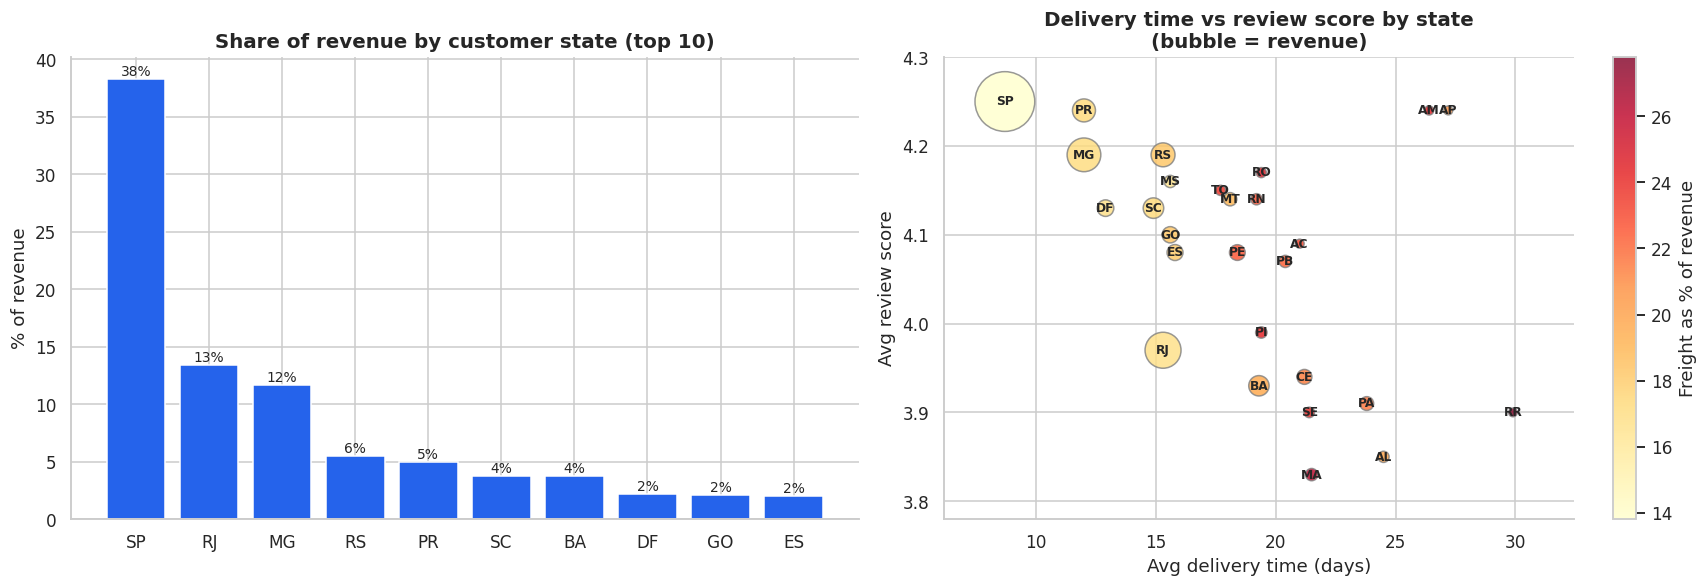


> 💡 **So what?**
> - **SP** alone is **38%** of revenue; the top 3 states are **63%** → heavy geographic concentration.
> - Across states, delivery time and review score are correlated at **r = -0.46** → slower regions tend to be less satisfied.
> - The slowest regions (**RR, AP, AM**) average **28 days** vs **13** overall, and freight there is **24%** of revenue vs **16.6%** overall — a candidate for **regional fulfilment hubs**.


In [11]:
geo = q("03_state_performance", '''
WITH sales AS (
    SELECT customer_state AS state,
           SUM(price)                         AS revenue,
           SUM(freight_value)                 AS freight,
           COUNT(DISTINCT customer_unique_id) AS customers
    FROM v_sales
    GROUP BY customer_state
),
logistics AS (
    SELECT customer_state AS state,
           AVG(delivery_days)   AS avg_delivery_days,
           100.0 * AVG(is_late) AS late_pct,
           AVG(review_score)    AS avg_review
    FROM v_delivered_orders
    GROUP BY customer_state
)
SELECT s.state,
       ROUND(s.revenue, 0)                              AS revenue,
       ROUND(100.0 * s.revenue / SUM(s.revenue) OVER (), 1) AS revenue_share_pct,
       s.customers,
       ROUND(100.0 * s.freight / s.revenue, 1)          AS freight_pct,
       ROUND(l.avg_delivery_days, 1)                    AS avg_delivery_days,
       ROUND(l.late_pct, 1)                             AS late_pct,
       ROUND(l.avg_review, 2)                           AS avg_review
FROM sales s
JOIN logistics l ON l.state = s.state
ORDER BY s.revenue DESC
''')
display(geo.head(10))

fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
t10 = geo.head(10)
ax[0].bar(t10.state, t10.revenue_share_pct, color=BLUE)
for i, v in enumerate(t10.revenue_share_pct):
    ax[0].text(i, v + .3, f"{v:.0f}%", ha="center", fontsize=9)
ax[0].set_title("Share of revenue by customer state (top 10)"); ax[0].set_ylabel("% of revenue")

g = geo[geo.customers >= 30]
sc = ax[1].scatter(g.avg_delivery_days, g.avg_review, s=g.revenue / g.revenue.max() * 1500 + 30,
                   c=g.freight_pct, cmap="YlOrRd", alpha=.8, edgecolor="grey")
for _, r in g.iterrows():
    ax[1].annotate(r.state, (r.avg_delivery_days, r.avg_review), ha="center", va="center", fontsize=8, fontweight="bold")
plt.colorbar(sc, ax=ax[1], label="Freight as % of revenue")
ax[1].set_xlabel("Avg delivery time (days)"); ax[1].set_ylabel("Avg review score")
ax[1].set_title("Delivery time vs review score by state\n(bubble = revenue)"); ax[1].margins(.12)
plt.tight_layout(); save_fig(fig, "03_geography"); plt.show()

corr = g[["avg_delivery_days", "avg_review"]].corr().iloc[0, 1]
worst = g.sort_values("avg_delivery_days", ascending=False).head(3)
avg_deliv = pd.read_sql_query("SELECT AVG(delivery_days) AS x FROM v_delivered_orders", con).x[0]
slow_days, slow_freight = worst.avg_delivery_days.mean(), worst.freight_pct.mean()
corr_txt = "slower regions tend to be less satisfied" if corr < -0.3 else "no strong state-level relationship"
say(f'''
> 💡 **So what?**
> - **{geo.state.iloc[0]}** alone is **{geo.revenue_share_pct.iloc[0]:.0f}%** of revenue; the top 3 states are **{geo.revenue_share_pct.head(3).sum():.0f}%** → heavy geographic concentration.
> - Across states, delivery time and review score are correlated at **r = {corr:.2f}** → {corr_txt}.
> - The slowest regions (**{', '.join(worst.state)}**) average **{slow_days:.0f} days** vs **{avg_deliv:.0f}** overall, and freight there is **{slow_freight:.0f}%** of revenue vs **{kpi.freight_pct_of_revenue}%** overall — a candidate for **regional fulfilment hubs**.
''')

## 8. Do late deliveries destroy satisfaction? (with a statistical test)
**SQL techniques:** CTE with `CASE` bucketing. **Statistics:** Mann-Whitney U test + effect size.

,delivery_bucket,orders,avg_review,pct_bad_reviews_1_2_stars
0,1. Early (7+ days),70690,4.32,9.00
1,2. On time,17218,4.20,10.20
2,3. Late 1-3 days,2633,3.76,19.20
3,4. Late 4-7 days,1773,2.32,61.30
4,5. Late 7+ days,3246,1.73,78.50


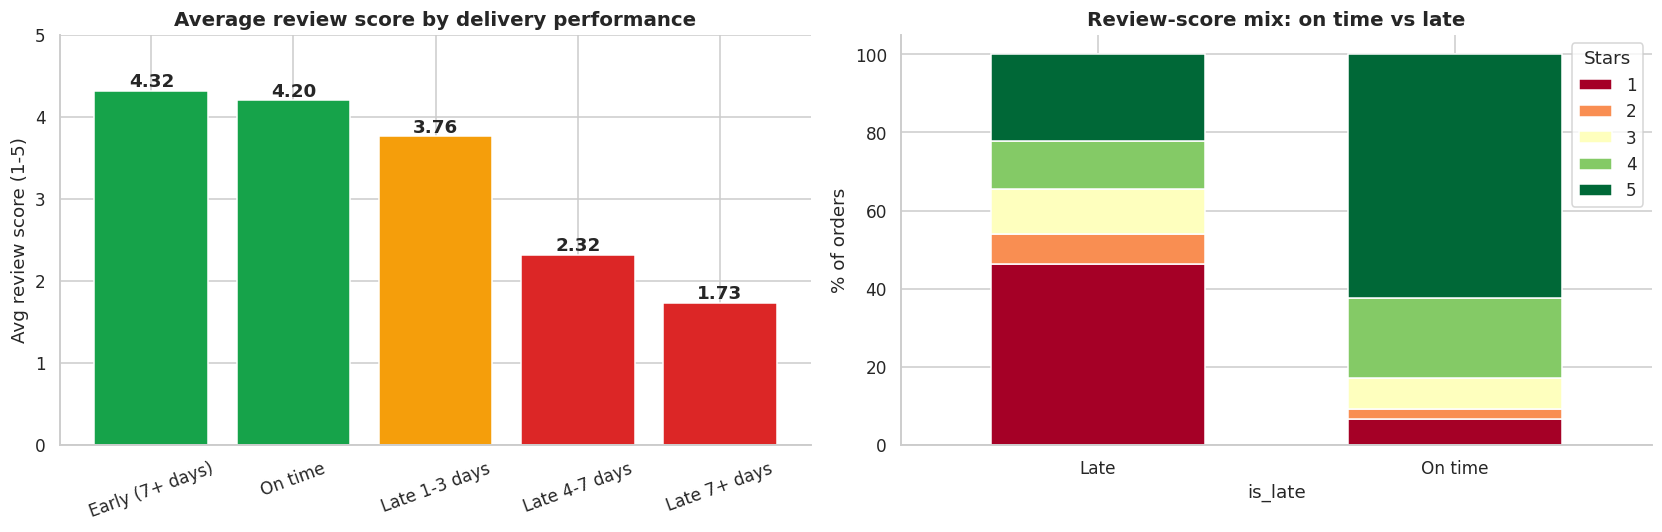


**Hypothesis test** — H₀: late and on-time orders get the same review scores.

| | n | mean score |
|---|---|---|
| On time | 87,902 | 4.29 |
| Late | 7,658 | 2.57 |

- Mean difference = **-1.73 stars** (95% CI -1.77 to -1.69)
- Cohen's d = **-1.21** (|d| > 0.8 is conventionally a *large* effect)
- Mann-Whitney U p-value **< 0.001** → reject H₀: the gap is statistically significant

> 💡 **So what?** Late orders are only **8.0%** of orders but account for **34% of all 1-2★ reviews**. Delivery reliability looks like a major, *controllable* driver of unhappy customers (this analysis does not test other drivers such as price or product quality).


In [12]:
dlv = q("04_delivery_vs_review", '''
WITH bucketed AS (
    SELECT order_id, review_score,
           CASE WHEN days_vs_estimate <= -7 THEN '1. Early (7+ days)'
                WHEN days_vs_estimate <=  0 THEN '2. On time'
                WHEN days_vs_estimate <=  3 THEN '3. Late 1-3 days'
                WHEN days_vs_estimate <=  7 THEN '4. Late 4-7 days'
                ELSE                             '5. Late 7+ days' END AS delivery_bucket
    FROM v_delivered_orders
    WHERE review_score IS NOT NULL
)
SELECT delivery_bucket,
       COUNT(*)                                          AS orders,
       ROUND(AVG(review_score), 2)                       AS avg_review,
       ROUND(100.0 * SUM(review_score <= 2) / COUNT(*), 1) AS pct_bad_reviews_1_2_stars
FROM bucketed
GROUP BY delivery_bucket
ORDER BY delivery_bucket
''')
display(dlv)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
cols = [GREEN, GREEN, ORANGE, RED, RED]
ax[0].bar(dlv.delivery_bucket.str[3:], dlv.avg_review, color=cols)
for i, v in enumerate(dlv.avg_review):
    ax[0].text(i, v + .05, f"{v:.2f}", ha="center", fontweight="bold")
ax[0].set_ylim(0, 5); ax[0].set_title("Average review score by delivery performance")
ax[0].tick_params(axis="x", rotation=20); ax[0].set_ylabel("Avg review score (1-5)")

orders_df = q("04b_orders_with_reviews", "SELECT order_id, is_late, review_score, days_vs_estimate FROM v_delivered_orders WHERE review_score IS NOT NULL")
dist = pd.crosstab(orders_df.is_late.map({0: "On time", 1: "Late"}), orders_df.review_score, normalize="index") * 100
dist.plot(kind="bar", stacked=True, ax=ax[1], colormap="RdYlGn", width=.6)
ax[1].set_title("Review-score mix: on time vs late"); ax[1].set_ylabel("% of orders"); ax[1].tick_params(axis="x", rotation=0)
ax[1].legend(title="Stars", bbox_to_anchor=(1, 1))
plt.tight_layout(); save_fig(fig, "04_delivery_vs_review"); plt.show()

# ---- Statistical test: is the gap real or noise?
late = orders_df[orders_df.is_late == 1].review_score
ontime = orders_df[orders_df.is_late == 0].review_score
u, p_val = stats.mannwhitneyu(late, ontime, alternative="less")
diff = late.mean() - ontime.mean()
se = np.sqrt(late.var() / len(late) + ontime.var() / len(ontime))
pooled_sd = np.sqrt((late.var() + ontime.var()) / 2)
p_txt = "< 0.001" if p_val < 0.001 else f"= {p_val:.3f}"
share_bad_late = 100 * ((orders_df.review_score <= 2) & (orders_df.is_late == 1)).sum() / (orders_df.review_score <= 2).sum()
say(f'''
**Hypothesis test** — H₀: late and on-time orders get the same review scores.

| | n | mean score |
|---|---|---|
| On time | {len(ontime):,} | {ontime.mean():.2f} |
| Late | {len(late):,} | {late.mean():.2f} |

- Mean difference = **{diff:.2f} stars** (95% CI {diff - 1.96*se:.2f} to {diff + 1.96*se:.2f})
- Cohen's d = **{diff / pooled_sd:.2f}** (|d| > 0.8 is conventionally a *large* effect)
- Mann-Whitney U p-value **{p_txt}** → {"reject H₀: the gap is statistically significant" if p_val < 0.05 else "cannot reject H₀"}

> 💡 **So what?** Late orders are only **{100*orders_df.is_late.mean():.1f}%** of orders but account for **{share_bad_late:.0f}% of all 1-2★ reviews**. Delivery reliability looks like a major, *controllable* driver of unhappy customers (this analysis does not test other drivers such as price or product quality).
''')

## 9. Do customers come back? Retention & cohort analysis
**SQL techniques:** 3 chained CTEs, `MIN()` per customer, `FIRST_VALUE()` window over an aggregate, `ROW_NUMBER()` + `COUNT() OVER (PARTITION BY …)`.

In [13]:
# 9.1 Order-frequency distribution
freq = q("05a_order_frequency", '''
WITH cust AS (
    SELECT customer_unique_id, COUNT(DISTINCT order_id) AS n_orders, SUM(price) AS spend
    FROM v_sales GROUP BY customer_unique_id
)
SELECT CASE WHEN n_orders = 1 THEN '1 order' WHEN n_orders = 2 THEN '2 orders' ELSE '3+ orders' END AS segment,
       COUNT(*)                                             AS customers,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)   AS pct_customers,
       ROUND(SUM(spend), 0)                                 AS revenue,
       ROUND(100.0 * SUM(spend) / SUM(SUM(spend)) OVER (), 1) AS pct_revenue
FROM cust GROUP BY segment ORDER BY segment
''')
display(freq)
repeat_rate = freq[freq.segment != "1 order"].pct_customers.sum()

,segment,customers,pct_customers,revenue,pct_revenue
0,1 order,91829,97.00,"12,702,405.00",94.40
1,2 orders,2639,2.80,"647,725.00",4.80
2,3+ orders,235,0.20,"99,400.00",0.70


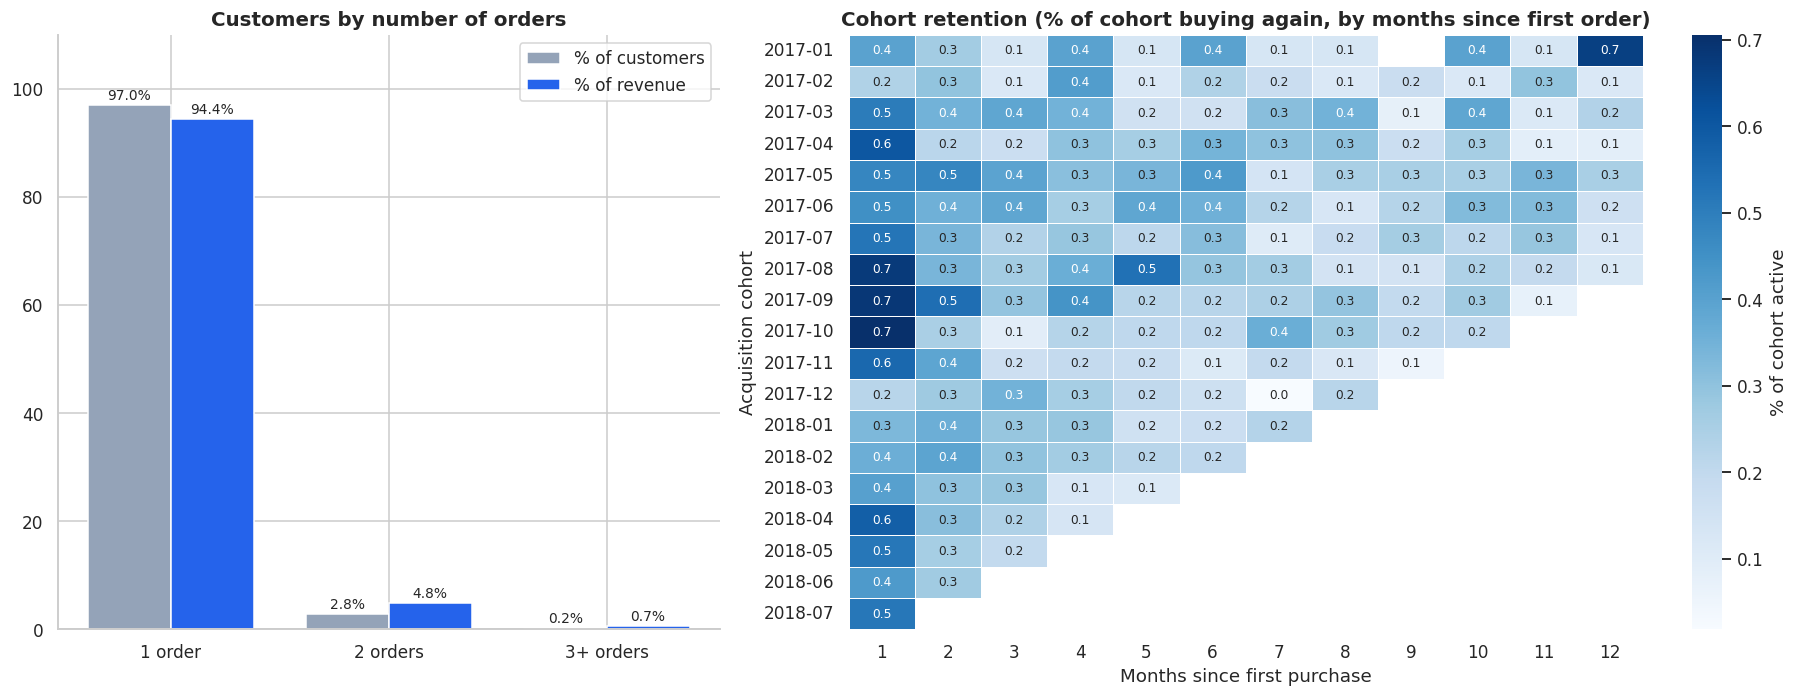

In [14]:
# 9.2 Monthly acquisition cohorts: what % of each cohort buys again in month 1, 2, 3 …?
cohort = q("05b_cohort_retention", '''
WITH first_order AS (
    SELECT customer_unique_id, MIN(order_month) AS cohort_month
    FROM v_sales GROUP BY customer_unique_id
),
activity AS (
    SELECT DISTINCT s.customer_unique_id, f.cohort_month, s.order_month
    FROM v_sales s
    JOIN first_order f ON f.customer_unique_id = s.customer_unique_id
),
indexed AS (
    SELECT cohort_month, customer_unique_id,
           (CAST(substr(order_month, 1, 4) AS INT) - CAST(substr(cohort_month, 1, 4) AS INT)) * 12
         + (CAST(substr(order_month, 6, 2) AS INT) - CAST(substr(cohort_month, 6, 2) AS INT)) AS months_since
    FROM activity
)
SELECT cohort_month, months_since,
       COUNT(DISTINCT customer_unique_id) AS active_customers,
       FIRST_VALUE(COUNT(DISTINCT customer_unique_id))
            OVER (PARTITION BY cohort_month ORDER BY months_since) AS cohort_size
FROM indexed
GROUP BY cohort_month, months_since
ORDER BY cohort_month, months_since
''')
cohort["retention_pct"] = 100 * cohort.active_customers / cohort.cohort_size
heat = cohort[(cohort.months_since.between(1, 12)) & (cohort.cohort_size >= 50)].pivot(
    index="cohort_month", columns="months_since", values="retention_pct")

fig, ax = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1, 1.5]})
xx = np.arange(len(freq)); w = .38
ax[0].bar(xx - w/2, freq.pct_customers, w, color=GREY, label="% of customers")
ax[0].bar(xx + w/2, freq.pct_revenue, w, color=BLUE, label="% of revenue")
for i, (a_, b_) in enumerate(zip(freq.pct_customers, freq.pct_revenue)):
    ax[0].text(i - w/2, a_ + 1, f"{a_:.1f}%", ha="center", fontsize=9); ax[0].text(i + w/2, b_ + 1, f"{b_:.1f}%", ha="center", fontsize=9)
ax[0].set_xticks(xx); ax[0].set_xticklabels(freq.segment); ax[0].set_ylim(0, 110); ax[0].legend()
ax[0].set_title("Customers by number of orders")
sns.heatmap(heat, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% of cohort active"}, ax=ax[1],
            linewidths=.5, annot_kws={"size": 8})
ax[1].grid(False); ax[1].set_title("Cohort retention (% of cohort buying again, by months since first order)")
ax[1].set_xlabel("Months since first purchase"); ax[1].set_ylabel("Acquisition cohort")
plt.tight_layout(); save_fig(fig, "05_retention_cohorts"); plt.show()

,first_experience,customers,repeat_rate_pct
0,Late first delivery,7599,2.50
1,On-time first delivery,85497,3.04


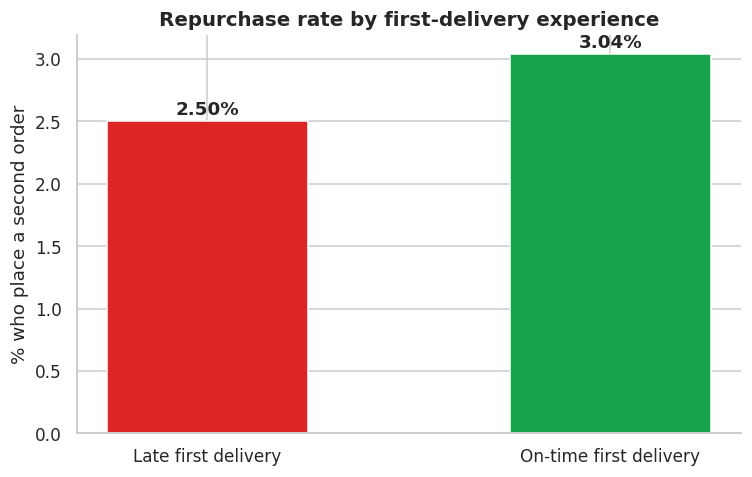


> 💡 **So what?**
> - Only **3.0%** of customers ever place a second order — Olist is effectively a **one-and-done marketplace**. Every customer acquired has to be re-acquired.
> - Customers whose first delivery was on time repurchase at **3.04%** vs **2.50%** for those whose first delivery was late (relative difference **+18%**). This is an *association*, not proof of causation — but it links logistics to lifetime value.


In [15]:
# 9.3 Does a bad FIRST delivery reduce the chance of a second purchase?
first_exp = q("05c_first_delivery_vs_repurchase", '''
WITH ranked AS (
    SELECT customer_unique_id, is_late,
           ROW_NUMBER() OVER (PARTITION BY customer_unique_id ORDER BY purchase_ts) AS order_seq,
           COUNT(*)     OVER (PARTITION BY customer_unique_id)                      AS total_orders
    FROM v_delivered_orders
)
SELECT CASE WHEN is_late = 1 THEN 'Late first delivery' ELSE 'On-time first delivery' END AS first_experience,
       COUNT(*)                                                 AS customers,
       ROUND(100.0 * SUM(total_orders > 1) / COUNT(*), 2)       AS repeat_rate_pct
FROM ranked
WHERE order_seq = 1
GROUP BY first_experience
''')
display(first_exp)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(first_exp.first_experience, first_exp.repeat_rate_pct, color=[RED if "Late" in x else GREEN for x in first_exp.first_experience], width=.5)
for i, v in enumerate(first_exp.repeat_rate_pct):
    ax.text(i, v + .05, f"{v:.2f}%", ha="center", fontweight="bold")
ax.set_ylabel("% who place a second order"); ax.set_title("Repurchase rate by first-delivery experience")
plt.tight_layout(); save_fig(fig, "05c_first_delivery_repurchase"); plt.show()

r_late = first_exp.loc[first_exp.first_experience.str.startswith("Late"), "repeat_rate_pct"].iloc[0]
r_ok = first_exp.loc[first_exp.first_experience.str.startswith("On-time"), "repeat_rate_pct"].iloc[0]
say(f'''
> 💡 **So what?**
> - Only **{repeat_rate:.1f}%** of customers ever place a second order — Olist is effectively a **one-and-done marketplace**. Every customer acquired has to be re-acquired.
> - Customers whose first delivery was on time repurchase at **{r_ok:.2f}%** vs **{r_late:.2f}%** for those whose first delivery was late (relative difference **{100*(r_ok-r_late)/r_ok:+.0f}%**). This is an *association*, not proof of causation — but it links logistics to lifetime value.
''')

## 10. Who are our most valuable customers? RFM segmentation
**RFM** = **R**ecency (days since last order), **F**requency (number of orders), **M**onetary (total spend).

**SQL techniques:** CTE chain, `CROSS JOIN` to a reference date, `NTILE(5)` window scoring, `CASE` segmentation.

> Frequency is scored with fixed rules (1 order → 1, 2 → 3, 3+ → 5) instead of `NTILE`, because ~97% of customers have exactly 1 order and quintiles on tied values would split identical customers into different groups.

,customers,revenue,avg_spend,avg_recency_days,pct_customers,pct_revenue
segment,,,,,,
New Big Spenders,14715,"3,942,048.30",267.90,91.20,15.50,29.30
At-Risk High Value,13921,"3,867,506.00",277.80,392.20,14.70,28.80
Needs Attention,18324,"2,393,122.80",130.60,219.00,19.30,17.80
Hibernating,22936,"1,278,187.90",55.70,392.40,24.20,9.50
Recent Customers,21933,"1,221,539.90",55.70,88.70,23.20,9.10
Loyal,1642,"414,733.50",252.60,319.60,1.70,3.10
Champions,1232,"332,391.20",269.80,88.10,1.30,2.50


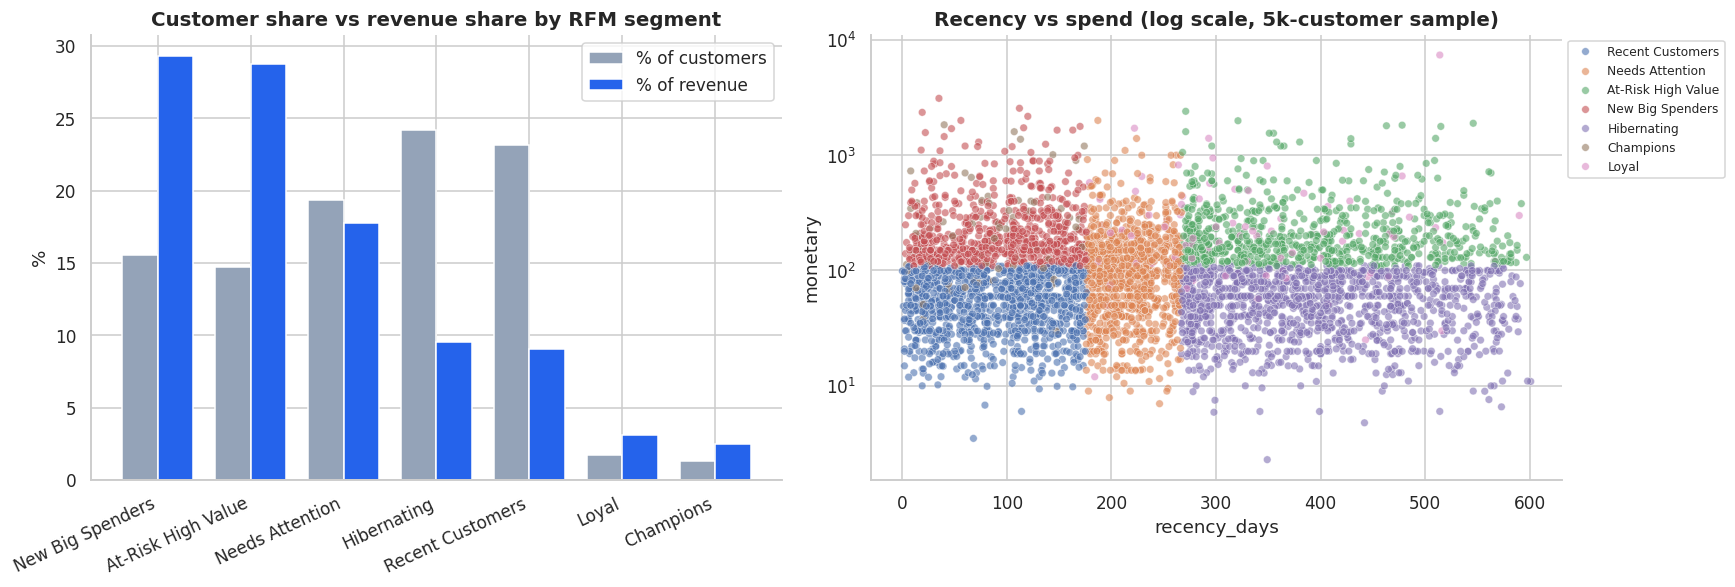


> 💡 **So what?**
> - **"At-Risk High Value"** customers: **13,921** people holding **R$3,867,506** of historic revenue (29% of the total) who have gone quiet → a win-back campaign target.
> - **"New Big Spenders"**: **14,715** recent high-value buyers (avg spend R$268) → ideal for a second-purchase incentive *now*, while they still remember the brand.
> - Repeat segments (Champions + Loyal) are tiny in customer count: loyalty is the biggest **untapped** opportunity.


In [16]:
rfm = q("06_rfm_segmentation", '''
WITH ref AS (
    SELECT MAX(purchase_ts) AS max_ts FROM v_sales
),
base AS (
    SELECT s.customer_unique_id,
           CAST(julianday(r.max_ts) - julianday(MAX(s.purchase_ts)) AS INT) AS recency_days,
           COUNT(DISTINCT s.order_id)                                       AS frequency,
           ROUND(SUM(s.price), 2)                                           AS monetary
    FROM v_sales s
    CROSS JOIN ref r
    GROUP BY s.customer_unique_id, r.max_ts
),
scored AS (
    SELECT *,
           NTILE(5) OVER (ORDER BY recency_days DESC) AS r_score,     -- 5 = bought most recently
           CASE WHEN frequency = 1 THEN 1 WHEN frequency = 2 THEN 3 ELSE 5 END AS f_score,
           NTILE(5) OVER (ORDER BY monetary ASC)      AS m_score      -- 5 = biggest spenders
    FROM base
)
SELECT *,
       CASE WHEN r_score >= 4 AND f_score >= 3 THEN 'Champions'
            WHEN f_score >= 3                  THEN 'Loyal'
            WHEN r_score >= 4 AND m_score >= 4 THEN 'New Big Spenders'
            WHEN r_score >= 4                  THEN 'Recent Customers'
            WHEN r_score <= 2 AND m_score >= 4 THEN 'At-Risk High Value'
            WHEN r_score <= 2                  THEN 'Hibernating'
            ELSE                                    'Needs Attention' END AS segment
FROM scored
''')

seg = (rfm.groupby("segment")
          .agg(customers=("customer_unique_id", "count"), revenue=("monetary", "sum"),
               avg_spend=("monetary", "mean"), avg_recency_days=("recency_days", "mean"))
          .assign(pct_customers=lambda d: 100 * d.customers / d.customers.sum(),
                  pct_revenue=lambda d: 100 * d.revenue / d.revenue.sum())
          .sort_values("revenue", ascending=False))
display(seg.round(1))

fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
x = np.arange(len(seg)); w = .38
ax[0].bar(x - w/2, seg.pct_customers, w, label="% of customers", color=GREY)
ax[0].bar(x + w/2, seg.pct_revenue, w, label="% of revenue", color=BLUE)
ax[0].set_xticks(x); ax[0].set_xticklabels(seg.index, rotation=25, ha="right")
ax[0].set_title("Customer share vs revenue share by RFM segment"); ax[0].legend(); ax[0].set_ylabel("%")
sample = rfm.sample(min(5000, len(rfm)), random_state=1)
sns.scatterplot(data=sample, x="recency_days", y="monetary", hue="segment", alpha=.6, s=25, ax=ax[1])
ax[1].set_yscale("log"); ax[1].set_title("Recency vs spend (log scale, 5k-customer sample)")
ax[1].legend(bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout(); save_fig(fig, "06_rfm_segments"); plt.show()

hv = seg.loc[["At-Risk High Value"]] if "At-Risk High Value" in seg.index else None
hv_pct = hv.pct_revenue.iloc[0] if hv is not None else 0.0
bs = seg.loc[["New Big Spenders"]] if "New Big Spenders" in seg.index else None
say(f'''
> 💡 **So what?**
> - **"At-Risk High Value"** customers: {f"**{hv.customers.iloc[0]:,.0f}** people holding **R${hv.revenue.iloc[0]:,.0f}** of historic revenue ({hv.pct_revenue.iloc[0]:.0f}% of the total) who have gone quiet → a win-back campaign target." if hv is not None else "n/a"}
> - **"New Big Spenders"**: {f"**{bs.customers.iloc[0]:,.0f}** recent high-value buyers (avg spend R${bs.avg_spend.iloc[0]:,.0f}) → ideal for a second-purchase incentive *now*, while they still remember the brand." if bs is not None else "n/a"}
> - Repeat segments (Champions + Loyal) are tiny in customer count: loyalty is the biggest **untapped** opportunity.
''')

## 11. Payments, sellers and shopping patterns

,payment_type,orders,total_value,pct_of_value,avg_payment,avg_installments
0,credit_card,75390,"12,308,515.00",78.50,162.65,3.50
1,boleto,19479,"2,817,575.00",18.00,144.65,1.00
2,voucher,3734,"348,891.00",2.20,62.41,1.00
3,debit_card,1513,"212,176.00",1.40,140.14,1.00


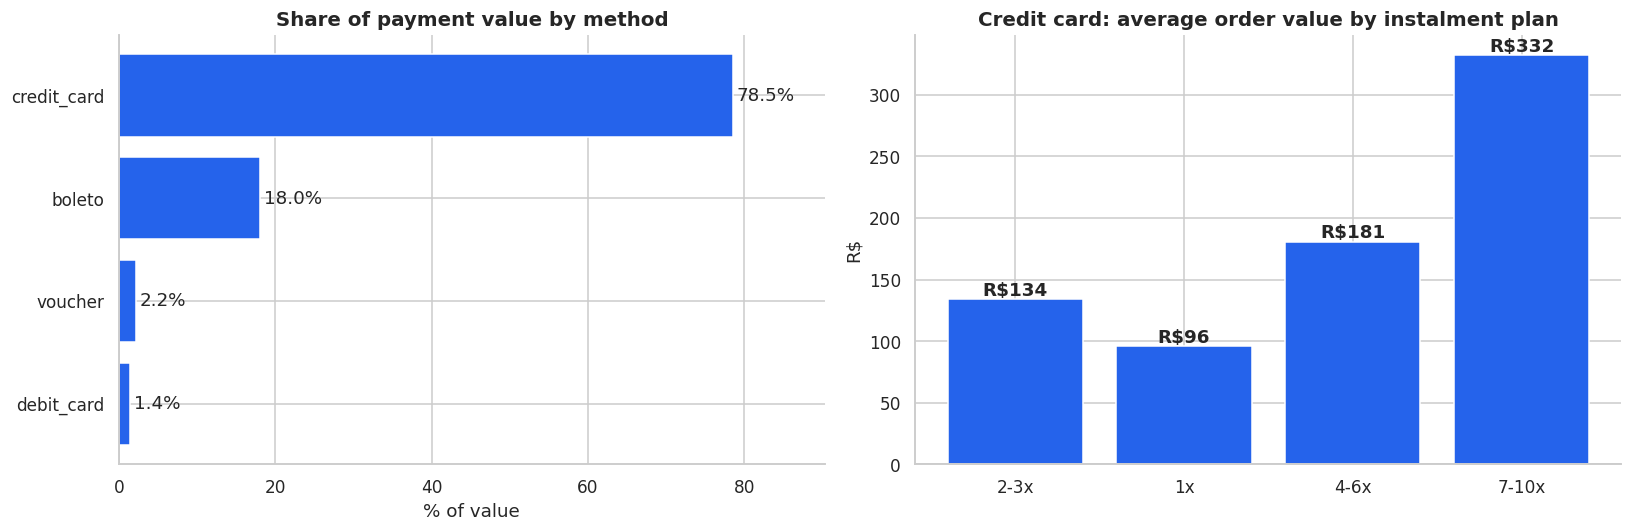


> 💡 **So what?** **credit_card** is **78%** of payment value. Orders paid in 7-10 instalments average **R$332** versus **R$134** for single payments → instalment financing **enables bigger baskets**; promote it on high-ticket categories.


In [17]:
# 11.1 Payment behaviour
pay = q("07a_payment_methods", f'''
SELECT p.payment_type,
       COUNT(DISTINCT p.order_id)                              AS orders,
       ROUND(SUM(p.payment_value), 0)                          AS total_value,
       ROUND(100.0 * SUM(p.payment_value) / SUM(SUM(p.payment_value)) OVER (), 1) AS pct_of_value,
       ROUND(AVG(p.payment_value), 2)                          AS avg_payment,
       ROUND(AVG(p.payment_installments), 1)                   AS avg_installments
FROM order_payments p
JOIN orders o ON o.order_id = p.order_id
WHERE o.order_status NOT IN ('canceled', 'unavailable')
  AND o.order_purchase_timestamp >= '{START_DATE}' AND o.order_purchase_timestamp < '{END_DATE}'
GROUP BY p.payment_type
ORDER BY total_value DESC
''')
display(pay)

inst = q("07b_installments_vs_order_value", f'''
SELECT CASE WHEN p.payment_installments = 1 THEN '1x'
            WHEN p.payment_installments <= 3 THEN '2-3x'
            WHEN p.payment_installments <= 6 THEN '4-6x'
            ELSE '7-10x' END                  AS installment_plan,
       COUNT(*)                               AS payments,
       ROUND(AVG(p.payment_value), 2)         AS avg_order_value
FROM order_payments p
JOIN orders o ON o.order_id = p.order_id
WHERE p.payment_type = 'credit_card'
  AND o.order_status NOT IN ('canceled', 'unavailable')
  AND o.order_purchase_timestamp >= '{START_DATE}' AND o.order_purchase_timestamp < '{END_DATE}'
GROUP BY installment_plan
ORDER BY MIN(p.payment_installments)
''')

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].barh(pay.payment_type[::-1], pay.pct_of_value[::-1], color=BLUE)
for i, v in enumerate(pay.pct_of_value[::-1]):
    ax[0].text(v + .5, i, f"{v:.1f}%", va="center")
ax[0].set_xlim(0, pay.pct_of_value.max() * 1.15); ax[0].set_title("Share of payment value by method"); ax[0].set_xlabel("% of value")
ax[1].bar(inst.installment_plan, inst.avg_order_value, color=BLUE)
for i, v in enumerate(inst.avg_order_value):
    ax[1].text(i, v + 3, f"R${v:,.0f}", ha="center", fontweight="bold")
ax[1].set_title("Credit card: average order value by instalment plan"); ax[1].set_ylabel("R$")
plt.tight_layout(); save_fig(fig, "07_payments"); plt.show()
say(f'''
> 💡 **So what?** **{pay.payment_type.iloc[0]}** is **{pay.pct_of_value.iloc[0]:.0f}%** of payment value. Orders paid in 7-10 instalments average **R${inst.avg_order_value.iloc[-1]:,.0f}** versus **R${inst.avg_order_value.iloc[0]:,.0f}** for single payments → instalment financing **enables bigger baskets**; promote it on high-ticket categories.
''')

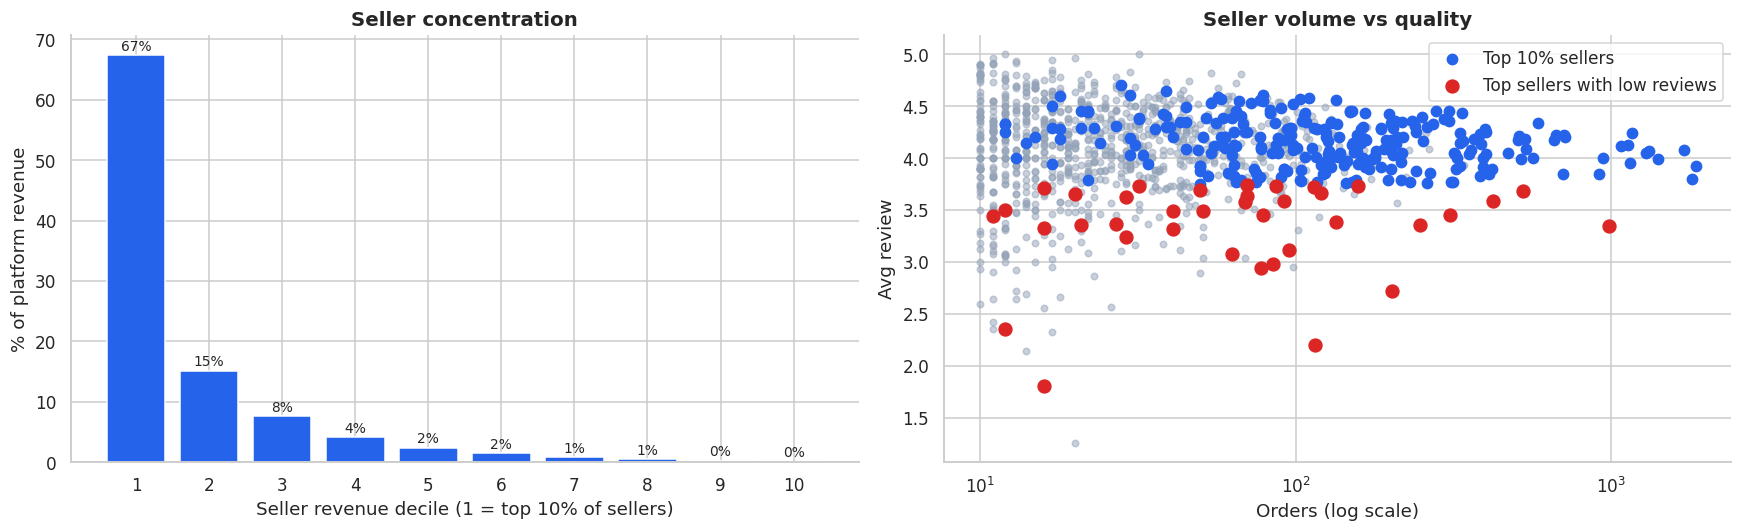

Seller watch-list (top-decile revenue, review score below platform average):


,seller_id,seller_state,revenue,orders,avg_review,revenue_rank
204,1ca7077d890b907f89be8c954a02686a,SP,"13,341.57",115,2.20,205
53,2eb70248d66e0e3ef83659f71b244378,SP,"42,628.61",202,2.72,54
269,54965bbe3e4f07ae045b90b0b8541f52,PR,"10,961.30",78,2.94,270
179,8e6d7754bc7e0f22c96d255ebda59eba,SP,"14,497.27",85,2.98,180
288,5058e8c1e82653974541e83690655b4a,SP,"10,022.82",63,3.08,289
117,8444e55c1f13cd5c179851e5ca5ebd00,MG,"21,967.96",95,3.12,118
245,d71d863e5ef30d94e440c11be17dcd8f,SP,"11,900.90",29,3.24,246
219,c60b801f2d52c7f7f91de00870882a75,SP,"12,913.50",41,3.32,220
4,7c67e1448b00f6e969d365cea6b010ab,SP,"187,923.89",982,3.35,5
289,054694fa03fe82cec4b7551487331d74,SP,"9,983.10",21,3.36,290



> 💡 **So what?** The **top 10% of sellers generate 67% of revenue**. Of those 303 sellers, **127** score below the platform average review and **37** are more than 0.3★ below it. A seller-quality programme should start with this short watch-list rather than spreading effort across hundreds of tiny sellers.


In [18]:
# 11.2 Seller performance & concentration
sellers = q("08_seller_ranking", '''
WITH seller_perf AS (
    SELECT seller_id,
           MAX(seller_state)           AS seller_state,
           SUM(price)                  AS revenue,
           COUNT(DISTINCT order_id)    AS orders,
           ROUND(AVG(review_score), 2) AS avg_review
    FROM v_sales
    GROUP BY seller_id
)
SELECT *,
       RANK()    OVER (ORDER BY revenue DESC) AS revenue_rank,
       NTILE(10) OVER (ORDER BY revenue DESC) AS revenue_decile
FROM seller_perf
ORDER BY revenue_rank
''')
decile = sellers.groupby("revenue_decile").agg(sellers=("seller_id", "count"), revenue=("revenue", "sum"))
decile["pct_revenue"] = 100 * decile.revenue / decile.revenue.sum()

# "Watch-list": top-decile sellers (by revenue) whose reviews are below the platform average
watch = (sellers[(sellers.revenue_decile == 1) & (sellers.orders >= 20) & (sellers.avg_review < kpi.avg_review_score)]
         .sort_values("avg_review").head(10)[["seller_id", "seller_state", "revenue", "orders", "avg_review", "revenue_rank"]])

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].bar(decile.index.astype(str), decile.pct_revenue, color=BLUE)
for i, v in enumerate(decile.pct_revenue):
    ax[0].text(i, v + .8, f"{v:.0f}%", ha="center", fontsize=9)
ax[0].set_xlabel("Seller revenue decile (1 = top 10% of sellers)"); ax[0].set_ylabel("% of platform revenue")
ax[0].set_title("Seller concentration")
s2 = sellers[sellers.orders >= 10]
ax[1].scatter(s2.orders, s2.avg_review, s=18, alpha=.5, color=GREY)
top_s = s2[s2.revenue_decile == 1]
ax[1].scatter(top_s.orders, top_s.avg_review, s=45, color=BLUE, label="Top 10% sellers")
bad_top = top_s[top_s.avg_review < kpi.avg_review_score - 0.3]
ax[1].scatter(bad_top.orders, bad_top.avg_review, s=70, color=RED, label="Top sellers with low reviews")
ax[1].set_xscale("log"); ax[1].set_xlabel("Orders (log scale)"); ax[1].set_ylabel("Avg review")
ax[1].set_title("Seller volume vs quality"); ax[1].legend()
plt.tight_layout(); save_fig(fig, "08_sellers"); plt.show()

print("Seller watch-list (top-decile revenue, review score below platform average):")
display(watch)
n_top = int((sellers.revenue_decile == 1).sum())
n_below = int(((sellers.revenue_decile == 1) & (sellers.avg_review < kpi.avg_review_score)).sum())
say(f'''
> 💡 **So what?** The **top 10% of sellers generate {decile.pct_revenue.iloc[0]:.0f}% of revenue**. Of those {n_top} sellers, **{n_below}** score below the platform average review and **{len(bad_top)}** are more than 0.3★ below it. A seller-quality programme should start with this short watch-list rather than spreading effort across hundreds of tiny sellers.
''')

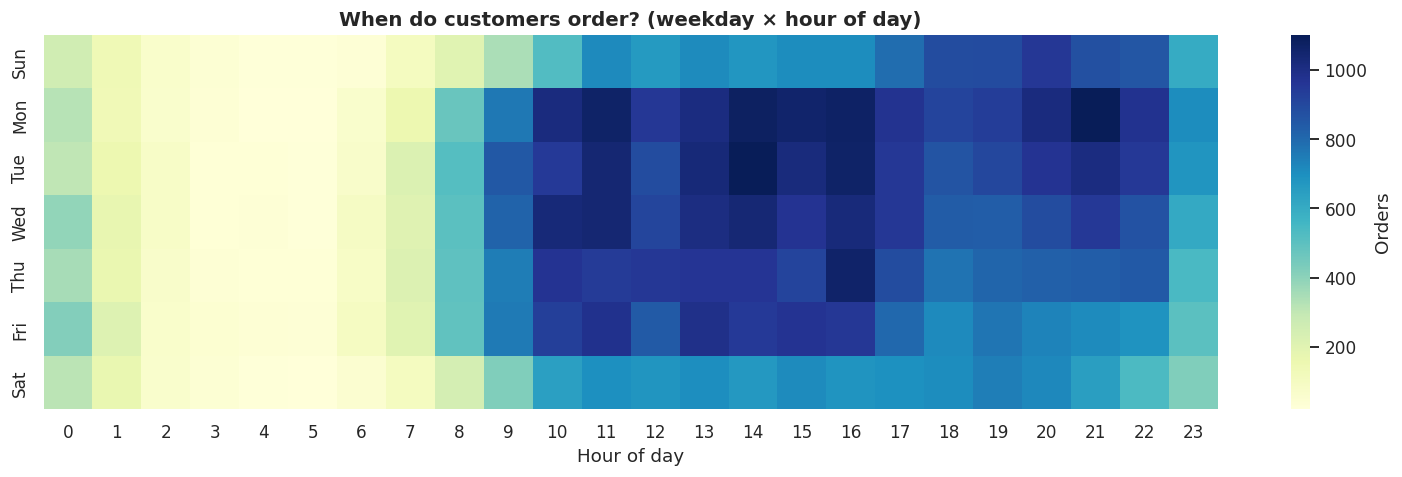

> 💡 **So what?** Orders peak on **Mon** and around **16:00**. Schedule promotions, e-mails and customer-service staffing around that window.

In [19]:
# 11.3 When do people shop?
when = q("09_orders_by_weekday_hour", '''
SELECT CAST(strftime('%w', purchase_ts) AS INT) AS weekday,
       CAST(strftime('%H', purchase_ts) AS INT) AS hour,
       COUNT(DISTINCT order_id)                 AS orders
FROM v_sales
GROUP BY weekday, hour
''')
days = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
grid = when.pivot(index="weekday", columns="hour", values="orders").reindex(range(7)).fillna(0)
grid.index = days

fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(grid, cmap="YlGnBu", ax=ax, cbar_kws={"label": "Orders"}); ax.grid(False)
ax.set_title("When do customers order? (weekday × hour of day)"); ax.set_xlabel("Hour of day")
plt.tight_layout(); save_fig(fig, "09_order_timing"); plt.show()

best_day = grid.sum(axis=1).idxmax(); best_hr = grid.sum(axis=0).idxmax()
say(f"> 💡 **So what?** Orders peak on **{best_day}** and around **{best_hr}:00**. Schedule promotions, e-mails and customer-service staffing around that window.")

## 12. Business scenario: what is bad delivery costing us?
A good analyst doesn't stop at "late deliveries are bad" — they size the prize.

**Scenario:** *if we halve the late-delivery rate for first-time customers, how much extra revenue comes from the extra repeat purchases?*

**Assumptions (change them and re-run):** the gap in repurchase rate between on-time and late first deliveries (Section 9) is causal, and repeat orders are worth the average order value. Treat this as a *directional estimate*, not a forecast.

In [20]:
REDUCTION = 0.50   # share of late first deliveries we fix  ← change me

late_first_customers = int(first_exp.loc[first_exp.first_experience.str.startswith("Late"), "customers"].iloc[0])
gap_pp = max(0.0, r_ok - r_late) / 100
extra_repeat_orders = late_first_customers * REDUCTION * gap_pp
incremental_revenue = extra_repeat_orders * kpi.avg_order_value
rev_share = 100 * incremental_revenue / kpi.revenue

say(f'''
| Input | Value |
|---|---|
| Customers whose first delivery was late | **{late_first_customers:,}** |
| Repurchase gap (on-time vs late) | **{gap_pp*100:.2f} percentage points** |
| Share of late deliveries fixed | **{REDUCTION:.0%}** |
| Avg order value | **R${kpi.avg_order_value:,.2f}** |

➡️ **≈ {extra_repeat_orders:,.0f} extra repeat orders ≈ R${incremental_revenue:,.0f} of incremental revenue ({rev_share:.2f}% uplift)** — before counting the savings from fewer complaints and refunds.
''')

# sensitivity table
sens = pd.DataFrame({f"{int(r*100)}% of late orders fixed": [late_first_customers * r * gap_pp * kpi.avg_order_value] for r in [.25, .5, .75, 1.0]},
                    index=["Incremental revenue (R$)"]).T
display(sens.style.format("R${:,.0f}"))


| Input | Value |
|---|---|
| Customers whose first delivery was late | **7,599** |
| Repurchase gap (on-time vs late) | **0.54 percentage points** |
| Share of late deliveries fixed | **50%** |
| Avg order value | **R$137.37** |

➡️ **≈ 21 extra repeat orders ≈ R$2,818 of incremental revenue (0.02% uplift)** — before counting the savings from fewer complaints and refunds.


,Incremental revenue (R$)
25% of late orders fixed,"R$1,409"
50% of late orders fixed,"R$2,818"
75% of late orders fixed,"R$4,228"
100% of late orders fixed,"R$5,637"


## 13. Executive dashboard (static) & Power BI export

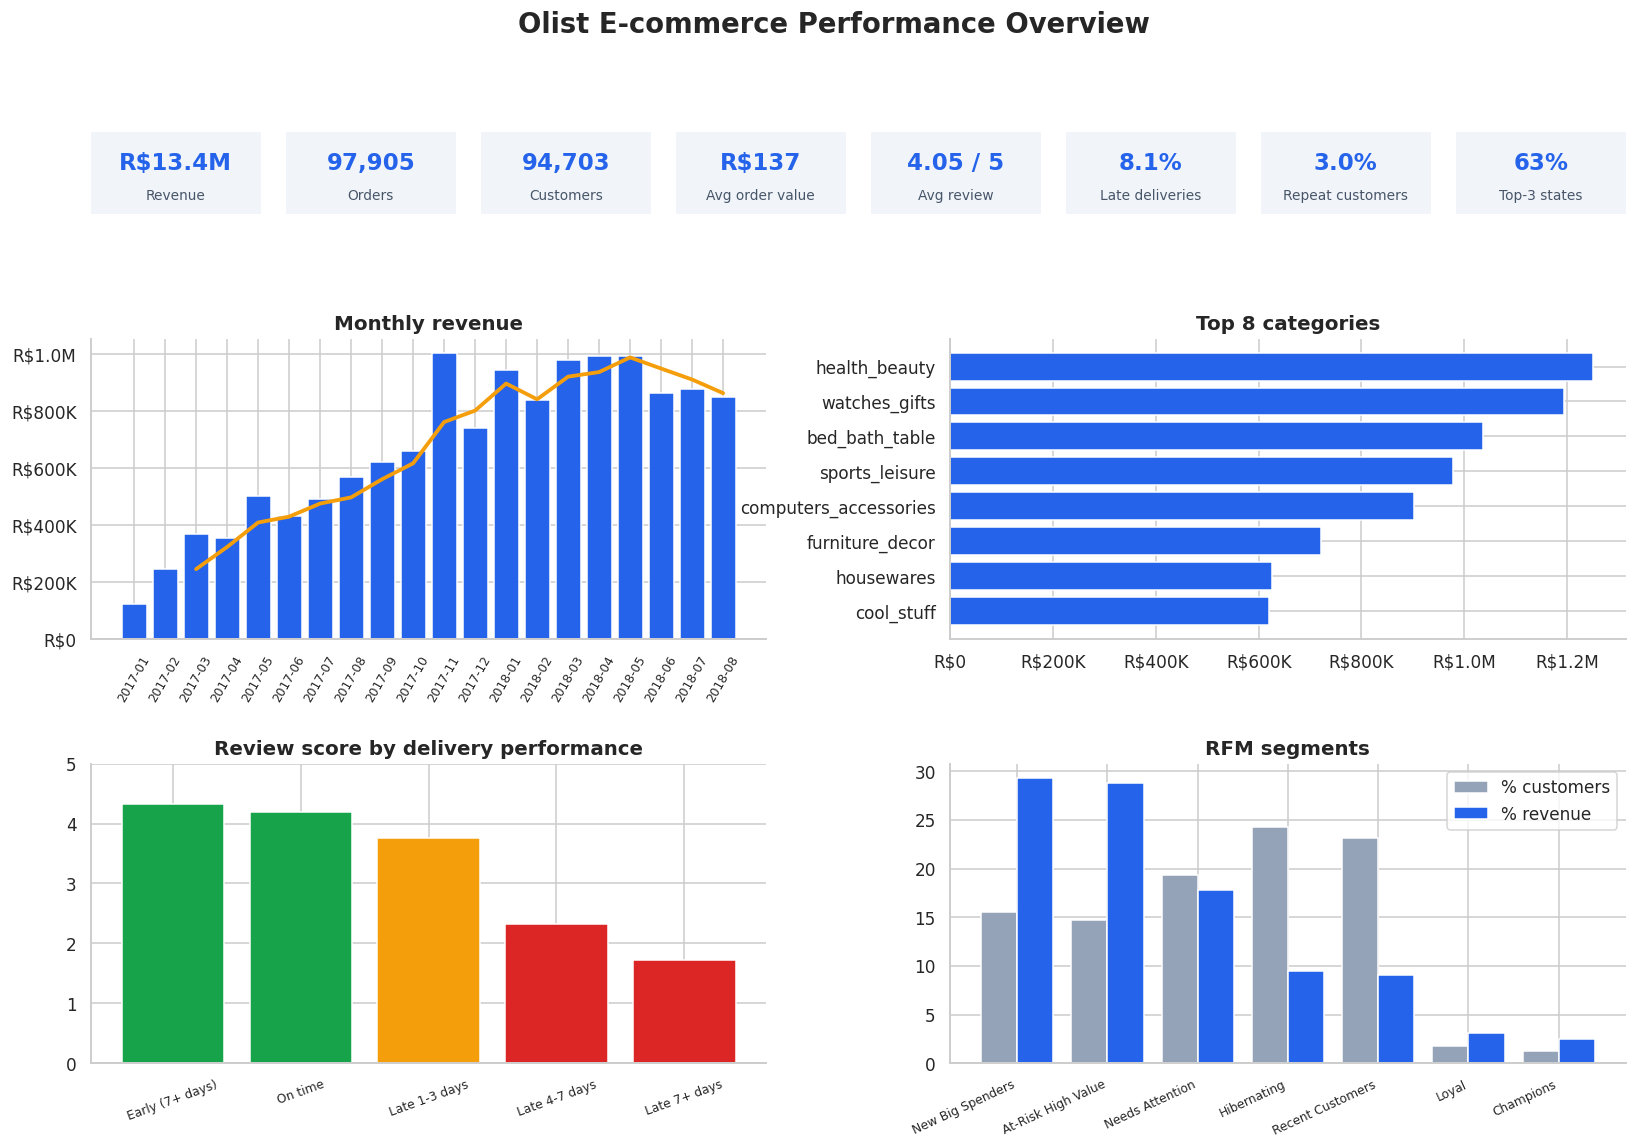

In [21]:
fig = plt.figure(figsize=(18, 11), facecolor="white")
gs = fig.add_gridspec(3, 4, height_ratios=[.55, 2, 2], hspace=.55, wspace=.75)

tiles = [("Revenue", f"R${kpi.revenue/1e6:.1f}M"), ("Orders", f"{kpi.orders:,.0f}"), ("Customers", f"{kpi.customers:,.0f}"),
         ("Avg order value", f"R${kpi.avg_order_value:,.0f}"), ("Avg review", f"{kpi.avg_review_score} / 5"),
         ("Late deliveries", f"{late_pct}%"), ("Repeat customers", f"{repeat_rate:.1f}%"), ("Top-3 states", f"{geo.revenue_share_pct.head(3).sum():.0f}%")]
tile_gs = gs[0, :].subgridspec(1, len(tiles), wspace=.15)
for i, (lab, val) in enumerate(tiles):
    a = fig.add_subplot(tile_gs[i]); a.axis("off")
    a.add_patch(plt.Rectangle((0, 0), 1, 1, color="#f1f5f9", transform=a.transAxes))
    a.text(.5, .62, val, ha="center", va="center", fontsize=15, fontweight="bold", color=BLUE, transform=a.transAxes)
    a.text(.5, .22, lab, ha="center", va="center", fontsize=9, color="#475569", transform=a.transAxes)

a1 = fig.add_subplot(gs[1, :2]); a1.bar(monthly.order_month, monthly.revenue, color=BLUE)
a1.plot(monthly.order_month, monthly.rev_3m_avg, color=ORANGE, lw=2.5)
a1.yaxis.set_major_formatter(mtick.FuncFormatter(brl)); a1.tick_params(axis="x", rotation=60, labelsize=8); a1.set_title("Monthly revenue")

a2 = fig.add_subplot(gs[1, 2:]); t8 = cat.head(8).iloc[::-1]
a2.barh(t8.category, t8.revenue, color=BLUE); a2.xaxis.set_major_formatter(mtick.FuncFormatter(brl)); a2.set_title("Top 8 categories")

a3 = fig.add_subplot(gs[2, :2]); a3.bar(dlv.delivery_bucket.str[3:], dlv.avg_review, color=cols)
a3.set_ylim(0, 5); a3.tick_params(axis="x", rotation=20, labelsize=8); a3.set_title("Review score by delivery performance")

a4 = fig.add_subplot(gs[2, 2:]); x = np.arange(len(seg))
a4.bar(x - .2, seg.pct_customers, .4, color=GREY, label="% customers"); a4.bar(x + .2, seg.pct_revenue, .4, color=BLUE, label="% revenue")
a4.set_xticks(x); a4.set_xticklabels(seg.index, rotation=25, ha="right", fontsize=8); a4.legend(); a4.set_title("RFM segments")

fig.suptitle("Olist E-commerce Performance Overview" + ("   [SYNTHETIC DEMO DATA]" if IS_SYNTHETIC else ""),
             fontsize=18, fontweight="bold", y=.98)
save_fig(fig, "dashboard_overview"); plt.show()

In [22]:
# Export clean, analysis-ready tables for Power BI / Tableau
fact_sales   = pd.read_sql_query("SELECT * FROM v_sales", con)
fact_orders  = pd.read_sql_query("SELECT * FROM v_delivered_orders", con)
exports = {
    "fact_sales": fact_sales, "fact_orders": fact_orders, "rfm_customers": rfm,
    "monthly_revenue": monthly, "category_summary": cat, "state_summary": geo,
    "cohort_retention": cohort, "seller_summary": sellers,
}
for name, df in exports.items():
    df.to_csv(f"powerbi/exports/{name}.csv", index=False)

# Save every SQL query (and the view definitions) as .sql files → shows up nicely on GitHub
Path("sql/00_create_views.sql").write_text(VIEWS_SQL.strip() + "\n")
for name, sql in QUERIES.items():
    Path(f"sql/{name}.sql").write_text(sql + ";\n")

print("Exported for Power BI:", ", ".join(f"{k}.csv" for k in exports))
print(f"Saved {len(QUERIES) + 1} SQL files to sql/ and charts to images/")

Exported for Power BI: fact_sales.csv, fact_orders.csv, rfm_customers.csv, monthly_revenue.csv, category_summary.csv, state_summary.csv, cohort_retention.csv, seller_summary.csv
Saved 15 SQL files to sql/ and charts to images/


## 14. Executive summary & recommendations

In [23]:
rec_cat = ", ".join(at_risk_cats.category.head(3)) if len(at_risk_cats) else "n/a"
say(f'''
### Key findings
1. **Growth** — Revenue reached R${kpi.revenue:,.0f} across {kpi.orders:,.0f} orders; Jan–Aug 2018 is {yoy:+.0f}% vs the same months of 2017. Growth comes from {growth_driver}, with a seasonal peak in {peak.order_month}.
2. **Concentration risk** — {n80} categories make 80% of revenue; {geo.state.iloc[0]} alone is {geo.revenue_share_pct.iloc[0]:.0f}% of revenue; the top 10% of sellers make {decile.pct_revenue.iloc[0]:.0f}%.
3. **Late delivery is strongly linked to bad reviews** — late orders are {100*orders_df.is_late.mean():.1f}% of orders but {share_bad_late:.0f}% of 1-2★ reviews (mean gap {diff:.2f}★, p {p_txt}).
4. **Retention is the biggest gap** — only {repeat_rate:.1f}% of customers buy twice. First-order delivery experience is associated with whether they return ({r_ok:.2f}% vs {r_late:.2f}%).

### Recommendations
| # | Action | Evidence | Expected impact |
|---|---|---|---|
| 1 | **Fix last-mile logistics in the slowest regions** (regional fulfilment hubs, realistic delivery promises) | Slowest states ({', '.join(worst.state)}) average {slow_days:.0f} days vs {avg_deliv:.0f} overall; delivery time vs review r = {corr:.2f} | Fewer bad reviews; ≈R${incremental_revenue:,.0f} from repeat purchases in the {REDUCTION:.0%} scenario |
| 2 | **Launch a 30-60 day post-purchase offer** aimed at "New Big Spenders" | Repeat rate is only {repeat_rate:.1f}% | Even +1pp repeat rate ≈ {kpi.customers*0.01:,.0f} extra customers retained |
| 3 | **Win-back campaign for "At-Risk High Value"** customers | {hv_pct:.0f}% of historic revenue sits with high-value customers who have gone quiet | Recover revenue from already-acquired, proven buyers |
| 4 | **Quality programme for big, low-rated categories** ({rec_cat}) and a **seller watch-list** | {len(at_risk_cats)} of the top-20 categories score below the platform average review | Protects the categories that matter most |
| 5 | **Promote instalments on high-ticket items; time campaigns to peak hours/season** | 7-10 instalment orders average R${inst.avg_order_value.iloc[-1]:,.0f} vs R${inst.avg_order_value.iloc[0]:,.0f} single-payment; orders peak on {best_day} ~{best_hr}:00 and in {peak.order_month} | Larger baskets, better marketing ROI |

### Limitations & next steps
- **No cost data** → this is a revenue analysis, not profitability. Margin by category would change the category ranking.
- **Correlation ≠ causation**: delivery→retention link is observational; an A/B test of a faster-shipping option would prove it.
- Dataset covers 2016-2018 and a single country (BRL); patterns may have shifted.
- **Next:** build a churn-prediction model, add sentiment analysis of review comments (Portuguese NLP), forecast monthly revenue.
''')


### Key findings
1. **Growth** — Revenue reached R$13,449,530 across 97,905 orders; Jan–Aug 2018 is +138% vs the same months of 2017. Growth comes from more orders rather than bigger baskets, with a seasonal peak in 2017-11.
2. **Concentration risk** — 18 categories make 80% of revenue; SP alone is 38% of revenue; the top 10% of sellers make 67%.
3. **Late delivery is strongly linked to bad reviews** — late orders are 8.0% of orders but 34% of 1-2★ reviews (mean gap -1.73★, p < 0.001).
4. **Retention is the biggest gap** — only 3.0% of customers buy twice. First-order delivery experience is associated with whether they return (3.04% vs 2.50%).

### Recommendations
| # | Action | Evidence | Expected impact |
|---|---|---|---|
| 1 | **Fix last-mile logistics in the slowest regions** (regional fulfilment hubs, realistic delivery promises) | Slowest states (RR, AP, AM) average 28 days vs 13 overall; delivery time vs review r = -0.46 | Fewer bad reviews; ≈R$2,818 from repeat purchases in the 50% scenario |
| 2 | **Launch a 30-60 day post-purchase offer** aimed at "New Big Spenders" | Repeat rate is only 3.0% | Even +1pp repeat rate ≈ 947 extra customers retained |
| 3 | **Win-back campaign for "At-Risk High Value"** customers | 29% of historic revenue sits with high-value customers who have gone quiet | Recover revenue from already-acquired, proven buyers |
| 4 | **Quality programme for big, low-rated categories** (watches_gifts, bed_bath_table, computers_accessories) and a **seller watch-list** | 7 of the top-20 categories score below the platform average review | Protects the categories that matter most |
| 5 | **Promote instalments on high-ticket items; time campaigns to peak hours/season** | 7-10 instalment orders average R$332 vs R$134 single-payment; orders peak on Mon ~16:00 and in 2017-11 | Larger baskets, better marketing ROI |

### Limitations & next steps
- **No cost data** → this is a revenue analysis, not profitability. Margin by category would change the category ranking.
- **Correlation ≠ causation**: delivery→retention link is observational; an A/B test of a faster-shipping option would prove it.
- Dataset covers 2016-2018 and a single country (BRL); patterns may have shifted.
- **Next:** build a churn-prediction model, add sentiment analysis of review comments (Portuguese NLP), forecast monthly revenue.


In [24]:
con.close()